<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/mlp-forecaster.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Multilayer perceptron forecaster

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

Neural networks that map a window of past values to future values are applied to records from every field of the doctoral school, for example climate station data, measurements on chemical reactors, ecological counts or physiological signals, whenever the relation between past and future is nonlinear and no model equations are known.

A forecasting model receives the past of a measured signal $s_1,s_2,\dots,s_k$ and returns the future values $\hat s_{k+\tau}$ for the leads $\tau=1,\dots,50$. The model is a multilayer perceptron (MLP), a neural network with one hidden layer of tanh units, which learns its nonlinear features of the past from the data. It reads the window of the last $L$ values and returns all 50 leads at once, one output per lead. This is a direct multi-horizon forecast, and no prediction is ever fed back as an input.

We work mainly with the intensity of the Santa Fe laser, a measured chaotic signal whose large pulses and sudden collapses are hard for linear models, and compare it with the Mackey–Glass delay equation at three delays, one periodic and two chaotic. The signal, forecasting protocol and scores determine the comparison. Persistence, which repeats the last value, a linear autoregressive (AR) model and a nonlinear vector autoregression (NVAR), which adds products of past values to the AR features, are fitted on the same data and are used as references. We implement the MLP with `flax.nnx`, represent its layers as nodes and edges, count its parameters, and train it by gradient descent with early stopping. The training and validation losses track the fit. The forecasts are compared with the references lead by lead and with the same network built and trained by scikit-learn, and a series of cheap experiments shows how the result depends on the window length, the hidden size, the random seed, the number of training epochs and the size of the training set. The same comparisons extend to the Mackey–Glass signals. The comparison with scikit-learn and the hyperparameter experiments go beyond the lecture, which uses the forecasts of Section 5 and the Mackey–Glass comparison of Section 8.

The implementation uses JAX. The network is a `flax.nnx` module, the optimiser comes from `optax`, and every training epoch is one jit-compiled program. The ridge regressions of the reference models are implemented in JAX and compared with scikit-learn, the NVAR features are compared with ReservoirPy, and the MLP implementation in JAX is compared with the scikit-learn `MLPRegressor`.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`. All cells took 3.8 minutes in this recorded CPU run. Wall times depend on hardware and concurrent system load.
> 2. `jax`, `flax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab. ReservoirPy is installed with `pip install reservoirpy`.
> 3. Upload the file `santafe_laser.txt` (Santa Fe laser data, set A) into a folder `data` next to the notebook.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # signals and ridge regressions in float64, networks in float32
import optax
import flax
from flax import nnx
import sklearn
from sklearn.linear_model import Ridge as SkRidge
from sklearn.neural_network import MLPRegressor
import copy
import reservoirpy
from reservoirpy.nodes import NVAR as RpyNVAR

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "MLP": dict(color="#7B4FA0", ls="-"),
         "sklearn MLP": dict(color="#2A9D8F", ls="-.")}
MODELS = ("persistence", "AR", "NVAR", "MLP")
MODELS_ALL = MODELS + ("sklearn MLP",)

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__,
      "| scikit-learn", sklearn.__version__, "| reservoirpy", reservoirpy.__version__)

jax 0.11.0 | flax 0.12.8 | optax 0.2.6 | scikit-learn 1.6.1 | reservoirpy 0.4.1


<hr/>
## 1. Santa Fe laser

The Santa Fe laser series is the measured output intensity of a single-mode far-infrared NH$_3$ laser, which oscillates at one frequency and amplifies light in a gas of ammonia molecules, recorded by Hübner, Abraham and Weiss [Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)]. It became data set A of the Santa Fe time series prediction competition [A. S. Weigend and N. A. Gershenfeld (eds.), *Time Series Prediction*, Addison-Wesley (1994), reissued by Routledge (2018), [doi:10.4324/9780429492648](https://doi.org/10.4324/9780429492648)]. The intensity is digitised to integers between 0 and 255 in arbitrary units. We use the first $N=4000$ samples.

The Mackey–Glass delay equation at the delays $\tau_{\rm MG}=15,25,35$ is generated as well and is compared with the laser in Section 8. Its generator integrates the delay equation by the fourth-order Runge–Kutta method with step 0.1, takes the delayed value at half steps by linear interpolation, starts from the constant history $s=1.2$, discards a transient and keeps one sample per time unit. Each signal is rescaled to $[0,1]$ with the minimum and maximum of its training block, the first 3000 samples, so the test block may slightly exceed this interval.

In [2]:
def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) is the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

# Common protocol: N = 4000 samples per signal; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the training block; horizons tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

sf_raw = santafe()          # measured intensity, arbitrary units
print(f"Santa Fe record: {len(sf_raw)} samples, intensity from {sf_raw.min():.0f} to {sf_raw.max():.0f} (arbitrary units)")
raw = {"SantaFe": sf_raw[:N_SAMPLES], "MG15": mackey_glass(15, N_SAMPLES),
       "MG25": mackey_glass(25, N_SAMPLES), "MG35": mackey_glass(35, N_SAMPLES)}
MG = ("MG15", "MG25", "MG35")
LABEL = {"SantaFe": "Santa Fe laser", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$"}
sig = {name: rescale01(x) for name, x in raw.items()}     # [0, 1] on the training block (first 3000 samples)
for name, s in sig.items():
    print(f"{name:8s} N = {len(s)}  train range [{s[:N_TRAIN].min():.2f}, {s[:N_TRAIN].max():.2f}]"
          f"  test range [{s[N_TRAIN:].min():.3f}, {s[N_TRAIN:].max():.3f}]")
nums["santafe_record_length"] = len(sf_raw)

# pulsation period = lag of the first maximum of the autocorrelation function on the training block
x = sig["SantaFe"][:N_TRAIN] - sig["SantaFe"][:N_TRAIN].mean()
acf = np.array([np.dot(x[:-l], x[l:]) / np.dot(x, x) for l in range(1, 30)])
lags = np.arange(1, 30)
is_max = (acf[1:-1] > acf[:-2]) & (acf[1:-1] > acf[2:])
T_PULSE = int(lags[1:-1][is_max][0])
print(f"first maximum of the autocorrelation function at lag {T_PULSE} (value {acf[T_PULSE - 1]:.2f})")
nums["santafe_pulse_period"] = T_PULSE

Santa Fe record: 10093 samples, intensity from 0 to 255 (arbitrary units)
SantaFe  N = 4000  train range [0.00, 1.00]  test range [0.004, 1.000]
MG15     N = 4000  train range [0.00, 1.00]  test range [0.000, 1.000]
MG25     N = 4000  train range [0.00, 1.00]  test range [-0.035, 1.027]
MG35     N = 4000  train range [0.00, 1.00]  test range [0.004, 0.990]
first maximum of the autocorrelation function at lag 8 (value 0.76)


The laser emits regular pulsations. Their period follows from the autocorrelation function $\rho(n)=\sum_k(s_k-\bar s)(s_{k+n}-\bar s)/\sum_k(s_k-\bar s)^2$ on the training block, whose first maximum lies at the printed lag. We plot the whole record $s_k$ with the three blocks of the chronological split, which are defined in the forecasting protocol. Over a few hundred samples the pulse amplitude grows, and then the intensity collapses at an irregular time and the growth starts again.

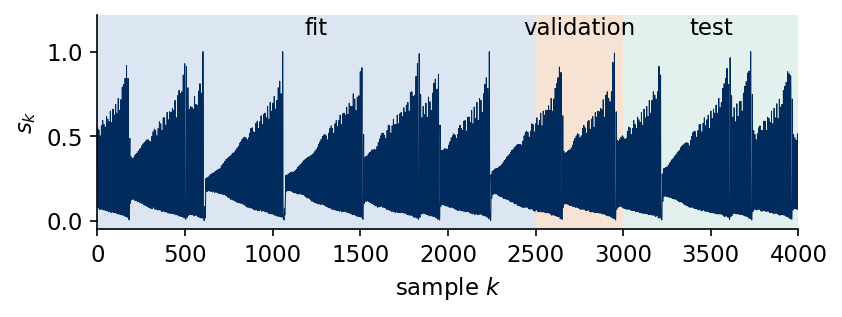

In [3]:
s = sig["SantaFe"]
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.0), layout="constrained")
    # shaded blocks of the chronological split
    for (a, b, c, lab) in ((0, N_TRAIN - N_VAL, "#DCE6F2", "fit"), (N_TRAIN - N_VAL, N_TRAIN, "#F6E3D3", "validation"),
                           (N_TRAIN, N_SAMPLES, "#E3F1EE", "test")):
        ax.axvspan(a, b, color=c, lw=0, zorder=0)
        ax.text(0.5 * (a + b), 1.07, lab, ha="center", va="bottom")
    ax.plot(np.arange(N_SAMPLES), s, color=UJNavy, lw=0.5)
    ax.set_xlim(0, N_SAMPLES); ax.set_ylim(-0.05, 1.22); ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("sample $k$"); ax.set_ylabel("$s_k$")
    save(fig, "fig_lab037_santafe_signal"); plt.show()

The left panel enlarges one collapse and the growth that follows it. The right panel plots $s_k$ against $s_{k-2}$ for all training samples, a two-dimensional delay embedding of the signal. Each pulsation is one turn of a spiral that winds outwards while the amplitude grows, and a collapse sends the trajectory back to the centre. Near the outer turns the future depends sensitively on the recent values, since a slightly different pulse can be followed either by a larger one or by a collapse. A forecast of the laser is therefore a strongly nonlinear function of the past window, which a weighted sum of past values cannot represent.

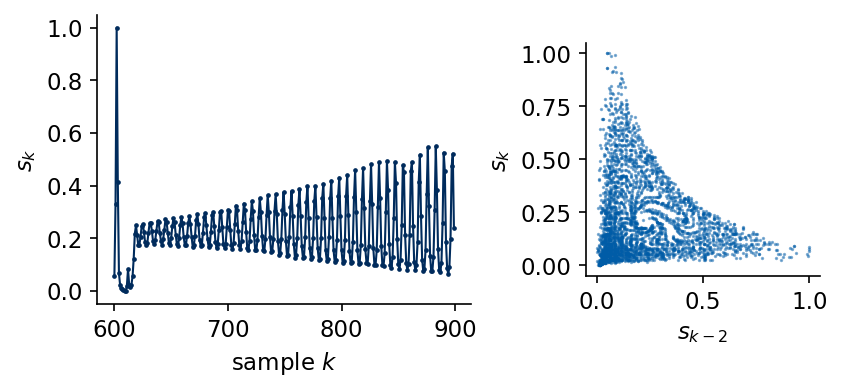

In [4]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained", gridspec_kw={"width_ratios": [1.6, 1]})
    kk = np.arange(600, 900)
    axs[0].plot(kk, s[kk], color=UJNavy, lw=1.0, marker=".", ms=2.5)
    axs[0].set_xlabel("sample $k$"); axs[0].set_ylabel("$s_k$"); axs[0].set_ylim(-0.05, 1.05)
    k2 = np.arange(2, N_TRAIN)
    axs[1].plot(s[k2 - 2], s[k2], ".", ms=1.2, color=UJBlue, alpha=0.5)
    axs[1].set_xlabel("$s_{k-2}$"); axs[1].set_ylabel("$s_k$")
    axs[1].set_xlim(-0.05, 1.05); axs[1].set_ylim(-0.05, 1.05); axs[1].set_aspect("equal")
    save(fig, "fig_lab037_santafe_zoom_delay"); plt.show()

### Forecasting protocol

The 4000 samples are split in time order. The first 3000 form the training block, and its last 500 samples are used for validation. The final 1000 samples are the test block. A forecast is made at an origin $k$ from the window of the last $L=64$ values, and the targets are the next 50 values,
$$\mathbf u_k=(s_{k-L+1},\dots,s_{k-1},s_k)\in\mathbb R^{L},\qquad \mathbf y_k=(s_{k+1},\dots,s_{k+50})\in\mathbb R^{50}.$$
The origins are chosen so that no target crosses a block boundary. Fitting uses the origins $k=63,\dots,2449$, whose targets lie inside the first 2500 samples, validation the origins $k=2499,\dots,2949$, and testing the origins $k=2999,\dots,3949$. A window may reach back into an earlier block, since its values are known at the time of the forecast.

In [5]:
L_WIN = 64                                                        # window length L
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)

def windows(s, ks, L=L_WIN):
    # inputs U[i] = (s_{k-L+1}, ..., s_k) and targets Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    assert ks.min() - L + 1 >= 0, "the window must not reach before the first sample"
    U = s[ks[:, None] + np.arange(-L + 1, 1)[None, :]]
    Y = s[ks[:, None] + TAUS[None, :]]
    return U, Y

U_tmp, Y_tmp = windows(sig["SantaFe"], K_TEST)
assert U_tmp.shape == (len(K_TEST), L_WIN) and Y_tmp.shape == (len(K_TEST), TAU_MAX)
assert U_tmp[0, -1] == sig["SantaFe"][K_TEST[0]] and Y_tmp[0, 0] == sig["SantaFe"][K_TEST[0] + 1]
assert (K_FIT + TAU_MAX).max() < N_TRAIN - N_VAL and (K_VAL + TAU_MAX).max() < N_TRAIN
assert K_TEST[0] + 1 == N_TRAIN and (K_TEST + TAU_MAX).max() == N_SAMPLES - 1
print(f"origins: fit {len(K_FIT)} ({K_FIT[0]}..{K_FIT[-1]}), validation {len(K_VAL)} ({K_VAL[0]}..{K_VAL[-1]}),"
      f" test {len(K_TEST)} ({K_TEST[0]}..{K_TEST[-1]})")
nums["protocol"] = dict(L=L_WIN, n_fit=len(K_FIT), n_val=len(K_VAL), n_test=len(K_TEST), tau_max=TAU_MAX)

origins: fit 2387 (63..2449), validation 451 (2499..2949), test 951 (2999..3949)


### Scores

For each lead $\tau$ we compare the forecasts $\hat s_{k+\tau}$ with the true values $s_{k+\tau}$ over the $n$ test origins with the Pearson correlation coefficient
$$r(\tau)=\frac{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_{\tau}\big)\big(s_{k+\tau}-\overline{s}_{\tau}\big)}{\sqrt{\sum_k\big(\hat s_{k+\tau}-\overline{\hat s}_{\tau}\big)^2\,\sum_k\big(s_{k+\tau}-\overline{s}_{\tau}\big)^2}},$$
where the bars denote averages over the test origins at fixed $\tau$. The forecast capacity $C(\tau)=r(\tau)^2\in[0,1]$ is the fraction of the variance of the target that a linear rescaling of the forecast explains. Its sum over the 50 leads, the total capacity
$$C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le 50,$$
summarises a whole curve. The skill horizon $\tau_{1/2}$ is the first lead with $C(\tau)<0.5$, and we write $\tau_{1/2}>50$ when the capacity stays above one half at all leads. The function `score` computes all of these from the arrays of forecasts and targets, and we check it against numpy on random data.

In [6]:
@jax.jit
def pearson_r(pred, true):
    # pred, true: (n, TAU_MAX); Pearson coefficient over the n origins, one value per lead
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    return jnp.sum(pc * tc, 0) / jnp.sqrt(jnp.sum(pc ** 2, 0) * jnp.sum(tc ** 2, 0))

def score(pred, true):
    # dictionary with r(tau), C(tau) = r^2, C_tot and the skill horizon tau_1/2
    r = np.asarray(pearson_r(jnp.asarray(pred, jnp.float64), jnp.asarray(true, jnp.float64)))
    C = r ** 2
    below = np.nonzero(C < 0.5)[0]
    return dict(r=r, C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

# check the JAX score against numpy on random data
rng = np.random.default_rng(0)
a, b = rng.normal(size=(500, TAU_MAX)), rng.normal(size=(500, TAU_MAX))
r_np = np.array([np.corrcoef(a[:, j] + 0.5 * b[:, j], b[:, j])[0, 1] for j in range(TAU_MAX)])
print("max |r_jax - r_numpy| =", np.abs(score(a + 0.5 * b, b)["r"] - r_np).max())

max |r_jax - r_numpy| = 6.106226635438361e-16


The JAX and numpy correlation coefficients agree to round-off, so the same function can score every model.

<hr/>
## 2. Persistence, AR and NVAR baselines

Persistence repeats the last value, $\hat s_{k+\tau}=s_k$, needs no fitting and sets the floor that any model must beat. The direct AR model of order $p$ and the NVAR model are ridge regressions on features of the delay vector $\mathbf d_k=(s_k,s_{k-1},\dots,s_{k-p+1})$,
$$\hat{\mathbf y}_k=W^\top\boldsymbol\phi(\mathbf d_k)+\mathbf b,\qquad \boldsymbol\phi_{\rm AR}=\mathbf d_k,\qquad \boldsymbol\phi_{\rm NVAR}=\big(\mathbf d_k,\ \{s_{k-i}s_{k-j}\}_{0\le i\le j<p}\big),$$
where $W$ has one column per lead and NVAR has $p+p(p+1)/2$ features [Gauthier *et al.*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. Ridge regression minimises $\sum_k\|\hat{\mathbf y}_k-\mathbf y_k\|^2+\beta\|W\|^2$. With centred features $\Phi_c$ and centred targets $Y_c$ the solution is
$$W=(\Phi_c^\top\Phi_c+\beta I)^{-1}\Phi_c^\top Y_c,\qquad \mathbf b=\bar{\mathbf y}-W^\top\bar{\boldsymbol\phi},$$
so the intercept $\mathbf b$ is left unpenalised. The order $p$ and the ridge strength $\beta$ are chosen by the largest $C_{\rm tot}$ on the validation origins, and the chosen model is scored once on the test origins.

In [7]:
def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = jnp.linalg.solve(Fc.T @ Fc + beta * jnp.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def delay_features(s, ks, p):
    # rows (s_k, s_{k-1}, ..., s_{k-p+1})
    return s[ks[:, None] - np.arange(p)[None, :]]

def nvar_features(s, ks, p):
    # delay vector and all quadratic monomials s_{k-i} s_{k-j}, i <= j
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}

def ridge_model(s, kind):
    # choose (p, beta) by validation C_tot, return the test predictions and the chosen setting
    _, Yf = windows(s, K_FIT); _, Yv = windows(s, K_VAL); _, Yt = windows(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    Ff, Ft = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_TEST, p)
    W, b = ridge_fit(Ff, Yf, beta)
    return dict(pred=np.asarray(Ft @ W + b), p=p, beta=beta, n_feat=Ff.shape[1], **score(Ft @ W + b, Yt))

res = {name: {} for name in sig}       # res[signal][model] = scores and predictions on the test origins
for name in sig:
    s = sig[name]
    U, Yt = windows(s, K_TEST)
    P_pers = np.repeat(U[:, -1:], TAU_MAX, 1)                # persistence: s_hat_{k+tau} = s_k
    res[name]["persistence"] = dict(pred=P_pers, **score(P_pers, Yt))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(s, kind)
    print(f"{name:8s} C_tot: persistence {res[name]['persistence']['Ctot']:5.1f} | "
          + " | ".join(f"{k} {res[name][k]['Ctot']:5.1f} (p={res[name][k]['p']}, beta={res[name][k]['beta']:.0e},"
                       f" {res[name][k]['n_feat']} features)" for k in ("AR", "NVAR")))

SantaFe  C_tot: persistence   5.5 | AR  16.5 (p=64, beta=1e+00, 64 features) | NVAR  34.7 (p=32, beta=1e-02, 560 features)
MG15     C_tot: persistence  19.5 | AR  49.8 (p=64, beta=1e-08, 64 features) | NVAR  50.0 (p=32, beta=1e-08, 560 features)
MG25     C_tot: persistence  13.3 | AR  33.1 (p=64, beta=1e-08, 64 features) | NVAR  45.5 (p=32, beta=1e-08, 560 features)
MG35     C_tot: persistence  11.8 | AR  38.0 (p=64, beta=1e-08, 64 features) | NVAR  48.6 (p=32, beta=1e-08, 560 features)


We list $C_{\rm tot}$ of the three references for all four signals, together with the order and ridge strength chosen on the validation origins. On the laser the quadratic features double the total capacity of the linear model, from 16.5 to 34.7. On the periodic Mackey–Glass signal at $\tau_{\rm MG}=15$ the linear model already reaches 49.8 of the possible 50, and at the two longer delays NVAR adds about ten units to AR. Every chosen AR model uses the longest order of the grid, $p=64$, which equals the window of the MLP of Section 3, and every NVAR model the longest NVAR order, $p=32$, with 560 features.

We repeat the two laser fits with scikit-learn. `Ridge` with `fit_intercept=True` also centres the data and leaves the intercept unpenalised, so it should return the same forecasts. ReservoirPy offers NVAR as a node that builds the delayed copies of the input and their monomials, and we check that its feature vector contains the same 560 numbers as ours.

In [8]:
s = sig["SantaFe"]
_, Yf = windows(s, K_FIT)
for kind in ("AR", "NVAR"):
    p, beta = res["SantaFe"][kind]["p"], res["SantaFe"][kind]["beta"]
    sk = SkRidge(alpha=beta, fit_intercept=True).fit(FEATS[kind](s, K_FIT, p), Yf)
    diff = np.abs(sk.predict(FEATS[kind](s, K_TEST, p)) - res["SantaFe"][kind]["pred"]).max()
    print(f"Santa Fe {kind} (p = {p}): max |prediction JAX - prediction scikit-learn| = {diff:.2e}")

# ReservoirPy builds the same NVAR feature vector (delays and quadratic monomials) in its own column order
p = res["SantaFe"]["NVAR"]["p"]
F_rpy = RpyNVAR(delay=p, order=2, strides=1).run(s[:, None])[K_TEST]
F_ours = nvar_features(s, K_TEST, p)
print(f"NVAR features, p = {p}: {F_rpy.shape[1]} in ReservoirPy, {F_ours.shape[1]} here,"
      f" max difference of the sorted feature rows {np.abs(np.sort(F_rpy, 1) - np.sort(F_ours, 1)).max():.1e}")

Santa Fe AR (p = 64): max |prediction JAX - prediction scikit-learn| = 1.39e-15
Santa Fe NVAR (p = 32): max |prediction JAX - prediction scikit-learn| = 2.92e-12
NVAR features, p = 32: 560 in ReservoirPy, 560 here, max difference of the sorted feature rows 0.0e+00


The forecasts of scikit-learn agree with ours to $10^{-15}$ for AR and $3\times10^{-12}$ for NVAR, the larger value coming from the worse conditioning of the 560 quadratic features. The ReservoirPy features coincide with ours after sorting each row, since the library orders the monomials differently.

<hr/>
## 3. Multilayer perceptron

The MLP replaces the fixed list of monomials of NVAR by features learned from the data. A hidden layer of $n_{\rm hid}$ tanh units reads the window and a linear layer maps the hidden activations to the 50 leads,
$$\mathbf h_k=\tanh\!\big(W_1\mathbf u_k+\mathbf b_1\big)\in\mathbb R^{n_{\rm hid}},\qquad \hat{\mathbf y}_k=W_2\mathbf h_k+\mathbf b_2\in\mathbb R^{50},$$
with $W_1\in\mathbb R^{n_{\rm hid}\times L}$, $\mathbf b_1\in\mathbb R^{n_{\rm hid}}$, $W_2\in\mathbb R^{50\times n_{\rm hid}}$ and $\mathbf b_2\in\mathbb R^{50}$. The tanh acts on each component separately, and component $\tau$ of $\hat{\mathbf y}_k$ is the forecast $\hat s_{k+\tau}$. All leads share the hidden features $\mathbf h_k$ and differ only in their row of $W_2$, the same structure as a ridge readout on a nonlinear feature vector, with the features now trained together with the readout. The network has
$$n_{\rm par}=(L+1)\,n_{\rm hid}+(n_{\rm hid}+1)\cdot 50$$
parameters, 7410 for $L=n_{\rm hid}=64$.

The universal approximation theorem states that such a network with enough hidden units approximates any continuous function on a compact set to any accuracy [Cybenko, Math. Control Signals Syst. **2**, 303 (1989), [doi:10.1007/BF02551274](https://doi.org/10.1007/BF02551274); Hornik, Neural Netw. **4**, 251 (1991), [doi:10.1016/0893-6080(91)90009-T](https://doi.org/10.1016/0893-6080(91)90009-T)]. The theorem says nothing about how many units a given task requires or whether gradient descent finds the weights, and the experiments of Section 7 explore both for the laser.

We draw the network as nodes and edges. Every column is a layer, every node of a column is connected to every node of the next one, and the dots mark columns with more nodes than drawn. The function `draw_layers` places the nodes, draws the edges first and the nodes on top, and returns the node positions for the labels.

parameters (L + 1) n_hid + (n_hid + 1) 50 = 65*64 + 65*50 = 7410


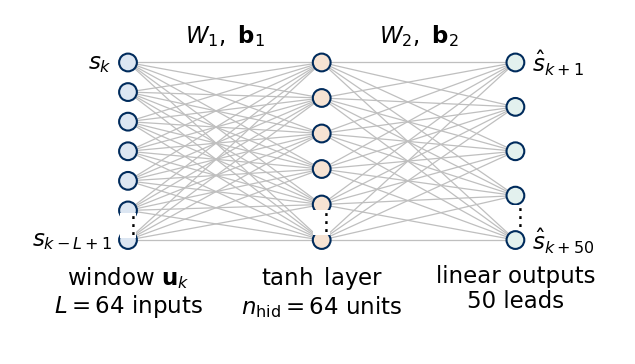

In [9]:
def draw_layers(ax, sizes, labels, xs, ys_span=2.2, node_r=0.11, colors=None, edge_color="0.75"):
    """Nodes-and-edges drawing of a fully connected network.

    sizes[i] nodes are placed in a vertical column at x = xs[i]; every node of a column is joined
    to every node of the next column (a dense layer); labels[i] is written below column i.
    Returns the node coordinates, one list of (x, y) per column, for further annotation.
    """
    cols = []
    for n, x in zip(sizes, xs):
        ys = np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0])
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):            # edges first, so that the nodes are drawn on top
        for (x0, y0) in a:
            for (x1, y1) in b:
                ax.plot([x0, x1], [y0, y1], color=edge_color, lw=0.6, zorder=1)
    for i, col in enumerate(cols):                    # nodes as circles, one fill colour per column
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=1.0, zorder=3))
    for i, lab in enumerate(labels):                  # one label per column, placed below it
        ax.text(xs[i], -ys_span / 2 - 0.3, lab, ha="center", va="top", linespacing=1.1)
    return cols

N_HID = 64
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.9))
    # 7, 6 and 5 drawn nodes stand for L = 64 inputs, 64 hidden units and 50 outputs
    cols = draw_layers(ax, [7, 6, 5], ["window $\\mathbf{u}_k$\n" + f"$L={L_WIN}$ inputs",
                                       "$\\tanh$ layer\n" + f"$n_{{\\rm hid}}={N_HID}$ units",
                                       "linear outputs\n" + f"{TAU_MAX} leads"],
                       xs=[0, 2.4, 4.8], colors=["#DCE6F2", "#F6E3D3", "#E3F1EE"])
    for (x, y), t in zip([cols[0][0], cols[0][-1]], [r"$s_k$", r"$s_{k-L+1}$"]):
        ax.text(x - 0.2, y, t, ha="right", va="center")
    for (x, y), t in zip([cols[2][0], cols[2][-1]], [r"$\hat s_{k+1}$", r"$\hat s_{k+50}$"]):
        ax.text(x + 0.2, y, t, ha="left", va="center")
    for col in cols:                                  # vertical dots: more nodes than drawn
        ax.text(col[0][0], 0.5 * (col[-2][1] + col[-1][1]), r"$\vdots$", ha="center", va="center", zorder=4,
                bbox=dict(fc="white", ec="none", pad=0.5))
    ax.text(1.2, 1.35, r"$W_1,\ \mathbf{b}_1$", ha="center"); ax.text(3.6, 1.35, r"$W_2,\ \mathbf{b}_2$", ha="center")
    ax.set_xlim(-1.4, 6.1); ax.set_ylim(-2.45, 1.7); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab037_mlp_architecture"); plt.show()

n_formula = (L_WIN + 1) * N_HID + (N_HID + 1) * TAU_MAX
print(f"parameters (L + 1) n_hid + (n_hid + 1) 50 = {L_WIN + 1}*{N_HID} + {N_HID + 1}*{TAU_MAX} = {n_formula}")

### MLP module in flax.nnx

The module holds the two dense layers. Its input has the shape $(B,L,1)$ of a batch of $B$ windows with one channel, and the call drops the channel axis, applies the hidden layer and the tanh, and returns an array of shape $(B,50)$. `nnx.Linear` initialises each weight matrix with the LeCun normal distribution, of variance $1/n_{\rm in}$ for $n_{\rm in}$ inputs, which keeps the pre-activations of order one for inputs of order one, and the biases with zeros [LeCun, Bottou, Orr and Müller, in *Neural Networks: Tricks of the Trade*, LNCS **1524**, 9 (1998), [doi:10.1007/3-540-49430-8_2](https://doi.org/10.1007/3-540-49430-8_2)]. The table produced by `nnx.tabulate` lists the layers, their shapes and their parameter counts.

In [10]:
class MLP(nnx.Module):
    def __init__(self, L, n_hid, n_out, *, rngs):
        self.l1 = nnx.Linear(L, n_hid, rngs=rngs)        # W_1, b_1
        self.l2 = nnx.Linear(n_hid, n_out, rngs=rngs)    # W_2, b_2
    def __call__(self, U):
        # U: (batch, L, 1) -> (batch, 50)
        return self.l2(jnp.tanh(self.l1(U[..., 0])))

def n_params(model):
    return int(sum(x.size for x in jax.tree.leaves(nnx.state(model, nnx.Param))))

mlp0 = MLP(L_WIN, N_HID, TAU_MAX, rngs=nnx.Rngs(0))
assert n_params(mlp0) == n_formula
print(nnx.tabulate(mlp0, jnp.ones((1, L_WIN, 1), jnp.float32), console_kwargs={"width": 100, "force_terminal": False}))
nums["n_params_mlp"] = n_formula

                                MLP Summary                                 
┏━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path ┃ type   ┃ inputs          ┃ outputs       ┃ Param                  ┃
┡━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│      │ MLP    │ float32[1,64,1] │ float32[1,50] │ 7,410 (29.6 KB)        │
├──────┼────────┼─────────────────┼───────────────┼────────────────────────┤
│ l1   │ Linear │ float32[1,64]   │ float32[1,64] │ bias: float32[64]      │
│      │        │                 │               │ kernel: float32[64,64] │
│      │        │                 │               │                        │
│      │        │                 │               │ 4,160 (16.6 KB)        │
├──────┼────────┼─────────────────┼───────────────┼────────────────────────┤
│ l2   │ Linear │ float32[1,64]   │ float32[1,50] │ bias: float32[50]      │
│      │        │                 │               │ kernel: float32[64,50] │
│      │        │                 │               │                        │
│      │        │                 │               │ 3,250 (13.0 KB)        │
├──────┼────────┼─────────────────┼───────────────┼────────────────────────┤
│      │        │                 │         Total │ 7,410 (29.6 KB)        │
└──────┴────────┴─────────────────┴───────────────┴────────────────────────┘
                                                                            
                     Total Parameters: 7,410 (29.6 KB)                      

The hidden layer holds $64\cdot64+64=4160$ parameters and the output layer $64\cdot50+50=3250$. Their sum 7410 agrees with the formula for $n_{\rm par}$, which the code also asserts. The kernel of `nnx.Linear` is stored as an $n_{\rm in}\times n_{\rm out}$ matrix, the transpose of $W_1$ and $W_2$ in our equations.

<hr/>
## 4. Training

The training set consists of the 2387 pairs $(\mathbf u_k,\mathbf y_k)$ of the fitting origins. Neighbouring windows overlap in $L-1$ values and are far from independent samples, so at every epoch we shuffle them and cut them into minibatches of $B=128$ windows. The loss is the mean-square error (MSE) over the minibatch and all 50 leads,
$$\mathcal L=\frac{1}{50\,B}\sum_{k\in\text{batch}}\big\|\hat{\mathbf y}_k-\mathbf y_k\big\|^2 ,$$
so every lead enters with the same weight. The Adam optimiser (adaptive moment estimation) with learning rate $5\times10^{-3}$ updates the weights with a step scaled by running estimates of the mean and the magnitude of each gradient component [Kingma and Ba, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)]. Before every update the gradient is rescaled when its Euclidean norm over all parameters exceeds 1.

After every epoch we compute the loss on the validation windows. We keep the parameters with the lowest validation loss and stop when it has not improved for 20 epochs, at most after 250 epochs. This early stopping [Prechelt, in *Neural Networks: Tricks of the Trade*, LNCS **1524**, 55 (1998), [doi:10.1007/3-540-49430-8_3](https://doi.org/10.1007/3-540-49430-8_3)] is the only regularisation of the network, and the test block is never used during training.

In the code, `nnx.split` separates the model into its structure (`graphdef`) and its parameters, which makes the loss a pure function of the parameters. `jax.value_and_grad` returns loss and gradient, `optax.chain(clip_by_global_norm, adam)` turns the gradient into an update, and one `jax.lax.scan` over the minibatches forms an epoch that `jax.jit` compiles once.

In [11]:
BATCH, LR, CLIP, MAX_EPOCHS, PATIENCE = 128, 5e-3, 1.0, 250, 20

def fit_network(model, data, seed=0, epochs=MAX_EPOCHS, patience=PATIENCE, verbose=True, keep_last=False):
    # data = (U_fit, Y_fit, U_val, Y_val), inputs of shape (n, L, 1), float32
    Uf, Yf, Uv, Yv = data
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.chain(optax.clip_by_global_norm(CLIP), optax.adam(LR))
    opt_state = tx.init(params)
    n = Uf.shape[0]; n_batches = n // BATCH

    def loss_fn(p, U, Y):
        return jnp.mean((nnx.merge(graphdef, p, rest)(U) - Y) ** 2)

    @jax.jit
    def epoch(p, opt_state, key):
        # one pass over the shuffled fitting windows in minibatches of BATCH windows
        idx = jax.random.permutation(key, n)[: n_batches * BATCH].reshape(n_batches, BATCH)
        def step(carry, ib):
            p, opt_state = carry
            loss, g = jax.value_and_grad(loss_fn)(p, Uf[ib], Yf[ib])
            upd, opt_state = tx.update(g, opt_state, p)
            return (optax.apply_updates(p, upd), opt_state), loss
        (p, opt_state), losses = jax.lax.scan(step, (p, opt_state), idx)
        return p, opt_state, losses.mean(), loss_fn(p, Uv, Yv)

    key = jax.random.key(seed)
    hist = dict(train=[], val=[])
    best_val, best_params, best_ep, t0 = np.inf, params, 0, time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, l_tr, l_va = epoch(params, opt_state, sub)
        hist["train"].append(float(l_tr)); hist["val"].append(float(l_va))
        if float(l_va) < best_val:
            best_val, best_params, best_ep = float(l_va), params, ep
        elif ep - best_ep >= patience:
            break
    hist = {k: np.array(v) for k, v in hist.items()}
    hist.update(best_epoch=best_ep + 1, epochs_run=ep + 1, time=time.time() - t0, best_val=best_val)
    if keep_last:
        hist["last_model"] = nnx.merge(graphdef, params, rest)
    if verbose:
        print(f"    {ep + 1:3d} epochs, best validation loss {best_val:.2e} at epoch {best_ep + 1},"
              f" {hist['time']:.1f} s")
    return nnx.merge(graphdef, best_params, rest), hist

def net_data(s, L=L_WIN, k_fit=K_FIT):
    # float32 windows (n, L, 1) and targets (n, 50) for fitting, validation and test origins
    out = []
    for ks in (k_fit, K_VAL, K_TEST):
        U, Y = windows(s, ks, L)
        out += [jnp.asarray(U[..., None], jnp.float32), jnp.asarray(Y, jnp.float32)]
    return out

def predict(model, U):
    return np.asarray(model(U), np.float64)

We train the MLP with $L=n_{\rm hid}=64$ and seed 0 on the laser and score it on the test origins.

In [12]:
data_sf = net_data(sig["SantaFe"])
Yv_sf, Yt_sf = np.asarray(data_sf[3], np.float64), np.asarray(data_sf[5], np.float64)
mlp_sf, hist_sf = fit_network(MLP(L_WIN, N_HID, TAU_MAX, rngs=nnx.Rngs(0)), data_sf[:4], seed=0)
res["SantaFe"]["MLP"] = dict(pred=predict(mlp_sf, data_sf[4]), **score(predict(mlp_sf, data_sf[4]), Yt_sf))
print(f"MLP ({n_params(mlp_sf)} parameters) on Santa Fe: test C_tot = {res['SantaFe']['MLP']['Ctot']:.1f},"
      f" {hist_sf['time'] / hist_sf['epochs_run'] * 1e3:.0f} ms per epoch")
nums["santafe_main"] = dict(epochs_run=hist_sf["epochs_run"], best_epoch=hist_sf["best_epoch"],
                            best_val=hist_sf["best_val"], final_train=float(hist_sf["train"][-1]),
                            time_s=hist_sf["time"], Ctot=res["SantaFe"]["MLP"]["Ctot"])

    250 epochs, best validation loss 1.12e-02 at epoch 244, 4.5 s
MLP (7410 parameters) on Santa Fe: test C_tot = 35.3, 18 ms per epoch


We plot the training loss $\mathcal L$, averaged over the minibatches of each epoch, and the validation loss, the same MSE over all validation windows, as functions of the epoch. The dotted line marks the epoch with the lowest validation loss, whose parameters are kept.

training loss: epoch 1 5.87e-02, last epoch 8.61e-03; validation loss: epoch 1 4.28e-02, best 1.12e-02


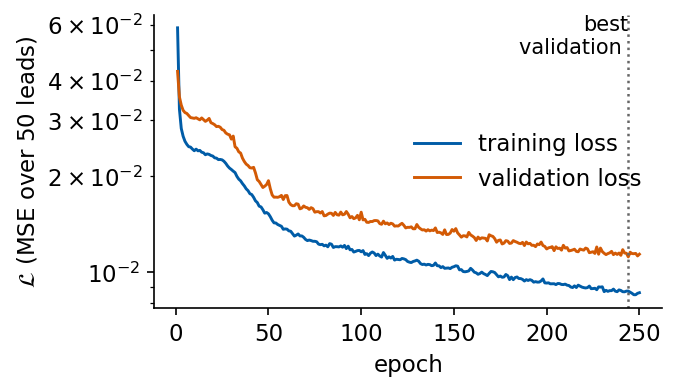

In [13]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    ep = np.arange(1, hist_sf["epochs_run"] + 1)
    ax.semilogy(ep, hist_sf["train"], color=UJBlue, label="training loss")
    ax.semilogy(ep, hist_sf["val"], color=DSOrange, label="validation loss")
    ax.axvline(hist_sf["best_epoch"], color="0.4", ls=":", lw=1.2)
    ax.text(hist_sf["best_epoch"], ax.get_ylim()[1], "best\nvalidation ", va="top", ha="right", fontsize=10)
    ax.set_xlabel("epoch"); ax.set_ylabel(r"$\mathcal{L}$ (MSE over 50 leads)")
    ax.legend(loc="center right")
    save(fig, "fig_lab037_loss_curves"); plt.show()
print(f"training loss: epoch 1 {hist_sf['train'][0]:.2e}, last epoch {hist_sf['train'][-1]:.2e};"
      f" validation loss: epoch 1 {hist_sf['val'][0]:.2e}, best {hist_sf['best_val']:.2e}")

Over the 250 epochs the training loss falls by a factor of about seven and the validation loss by a factor of about four, and both still decrease at the end. The lowest validation loss is reached at epoch 244, so the 20-epoch patience never triggered and the cap of 250 epochs ended the training. The validation loss stays above the training loss throughout, with no sign of a rise that would indicate overfitting. Section 7 measures the effect of longer training.

<hr/>
## 5. Forecasts of the laser

We compare the capacity curves $C(\tau)=r(\tau)^2$ of the four models on the test origins, with $C_{\rm tot}$ in the legend. The grey horizontal line marks $C=0.5$, which defines the skill horizon.

model         C_tot  tau_1/2    C(1)    C(5)   C(10)   C(25)   C(50)
persistence     5.5        1   0.269   0.193   0.098   0.034   0.000
AR             16.5       16   0.848   0.767   0.596   0.232   0.056
NVAR           34.7       42   0.983   0.928   0.868   0.701   0.381
MLP            35.3       49   0.934   0.893   0.853   0.688   0.464


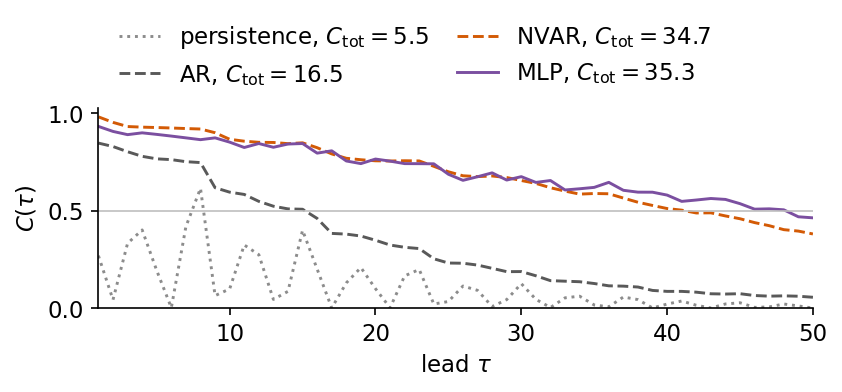

In [14]:
def capacity_plot(name, fname, title=None, models=MODELS):
    with mpl.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(5.5, 2.5), layout="constrained")
        for m in models:
            r_ = res[name][m]
            ax.plot(TAUS, r_["C"], label=f"{m}, $C_{{\\rm tot}}={r_['Ctot']:.1f}$", **STYLE[m])
        ax.axhline(0.5, color="0.75", lw=0.8)
        ax.set_xlim(1, TAU_MAX); ax.set_ylim(0, 1.03)
        ax.set_xlabel(r"lead $\tau$"); ax.set_ylabel(r"$C(\tau)$")
        if title: ax.set_title(title, loc="left")
        ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, handlelength=1.8, columnspacing=1.2)
        save(fig, fname); plt.show()

capacity_plot("SantaFe", "fig_lab037_capacity_santafe")
print(f"{'model':12s} {'C_tot':>6s} {'tau_1/2':>8s}" + "".join(f"{'C(' + str(t) + ')':>8s}" for t in (1, 5, 10, 25, 50)))
for m in MODELS:
    r_ = res["SantaFe"][m]
    print(f"{m:12s} {r_['Ctot']:6.1f} {str(r_['tau_half'] or '>50'):>8s}" + "".join(f"{r_['C'][t - 1]:8.3f}" for t in (1, 5, 10, 25, 50)))
nums["santafe"] = {m: dict(Ctot=res["SantaFe"][m]["Ctot"], tau_half=res["SantaFe"][m]["tau_half"],
                           C={t: float(res["SantaFe"][m]["C"][t - 1]) for t in (1, 2, 5, 10, 25, 50)}) for m in MODELS}
nums["ridge_choice"] = {n: {m: dict(p=res[n][m]["p"], beta=res[n][m]["beta"], n_feat=res[n][m]["n_feat"])
                            for m in ("AR", "NVAR")} for n in sig}

Persistence oscillates with the pulsation period and reaches $C_{\rm tot}=5.5$. The AR model starts at $C(1)=0.85$, falls below one half at $\tau_{1/2}=16$ and gives $C_{\rm tot}=16.5$. NVAR and the MLP reach $C_{\rm tot}=34.7$ and $35.3$, twice the linear value. NVAR is better at the shortest leads, with $C(1)=0.98$ against $0.93$, the two curves nearly coincide between $\tau\approx10$ and $\tau\approx30$, and the MLP decays more slowly at the longest leads, $C(50)=0.46$ against $0.38$, so its skill horizon is $\tau_{1/2}=49$ against 42. The difference in $C_{\rm tot}$ between the two nonlinear models, 0.6, is comparable to the spread over random seeds measured in Section 7.

### Forecasts at four leads

A capacity value summarises a whole lead in one number. To relate these numbers to the signal, we plot the MLP forecasts at the leads $\tau=1,2,5,10$. The upper panels show the target $s_{k+\tau}$ (black) and the forecast $\hat s_{k+\tau}$ (dashed) over 100 consecutive test targets that contain the largest collapse of the test block, located by the largest drop of the running maximum of the signal. The lower panels plot the forecast against the target for all 951 test origins, with $C(\tau)$ in the title and the diagonal $\hat s=s$ dotted.

largest envelope drop in the test block near sample 3205; plotted targets 3145..3244


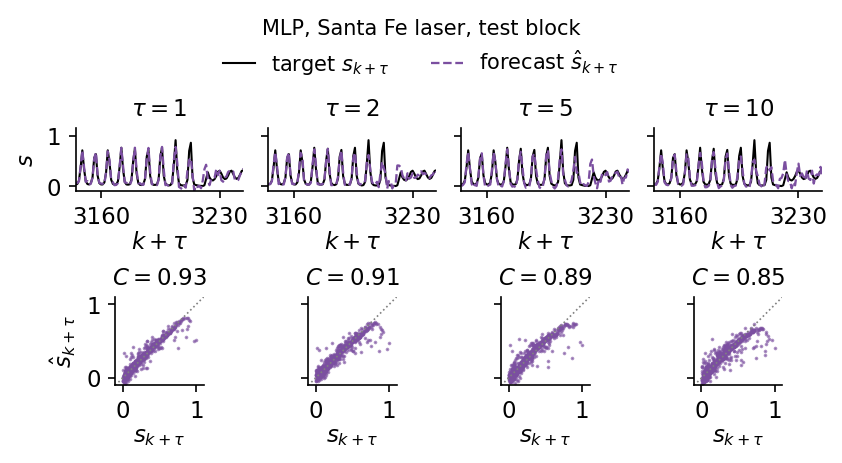

In [15]:
TAU_SHOW, K_SHOW = (1, 2, 5, 10), 100
# the plotted stretch of 100 targets contains the largest drop of the pulse envelope in the test block
s = sig["SantaFe"]
env = np.array([s[i:i + 20].max() for i in range(N_TRAIN, N_SAMPLES - 20)])     # running maximum over 20 samples
drop = env[:-40] - env[40:]
k_collapse = N_TRAIN + int(np.argmax(drop)) + 20
k0 = k_collapse - 60                                                            # first plotted target index
print(f"largest envelope drop in the test block near sample {k_collapse}; plotted targets {k0}..{k0 + K_SHOW - 1}")

def leads_figure(m, fname, name="SantaFe", k0=k0):
    # upper row: target and forecast on 100 consecutive test targets starting at k0; lower row: forecast vs target
    P, col = res[name][m]["pred"], STYLE[m]["color"]
    Yt_ = windows(sig[name], K_TEST)[1]
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(2, 4, figsize=(5.5, 3.0), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
        for c_, t in enumerate(TAU_SHOW):
            a_t, a_s = axs[0, c_], axs[1, c_]
            y_t, y_p = Yt_[:, t - 1], P[:, t - 1]
            Cv = float(np.corrcoef(y_p, y_t)[0, 1] ** 2)
            nums.setdefault("leads", {})[f"{name} {m} {t}"] = Cv
            i0 = k0 - t - K_TEST[0]                       # row of the origin whose target s_{k+tau} is s_{k0}
            kk = np.arange(k0, k0 + K_SHOW)
            a_t.plot(kk, y_t[i0:i0 + K_SHOW], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
            a_t.plot(kk, y_p[i0:i0 + K_SHOW], "--", color=col, lw=1.1, label=r"forecast $\hat s_{k+\tau}$")
            a_t.set_title(rf"$\tau={t}$"); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
            a_t.set_xlim(k0, k0 + K_SHOW - 1)
            a_t.set_xticks([k0 + 15, k0 + 85]); a_t.set_xlabel(r"$k+\tau$", labelpad=1)
            a_s.plot(y_t, y_p, ".", ms=1.5, color=col, alpha=0.6)
            a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
            a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
            a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel(r"$s_{k+\tau}$", labelpad=1)
            a_s.set_title(f"$C={Cv:.2f}$")
            if c_ > 0:
                a_t.set_yticklabels([]); a_s.set_yticklabels([])
        axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+\tau}$")
        fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=10,
                   handlelength=1.5, title=f"{m}, {LABEL[name]}, test block", title_fontsize=10)
        save(fig, fname); plt.show()

leads_figure("MLP", "fig_lab037_leads_mlp")

The MLP follows the growing pulses at all four leads. At the collapse the forecasts at $\tau=5$ and $\tau=10$ continue with a large pulse that never comes and then return to the low intensity after the collapse, since the window before a collapse looks much like a window before a further growth. In the scatter plots the cloud stays close to the diagonal for small and medium intensities and bends below it for targets above about 0.7, so the largest pulses are underestimated.

The same plot for the AR model displays the limit of a linear forecast.

Santa Fe C(tau) at tau = 1, 2, 5, 10
AR       0.848   0.830   0.767   0.596
MLP      0.934   0.908   0.893   0.853


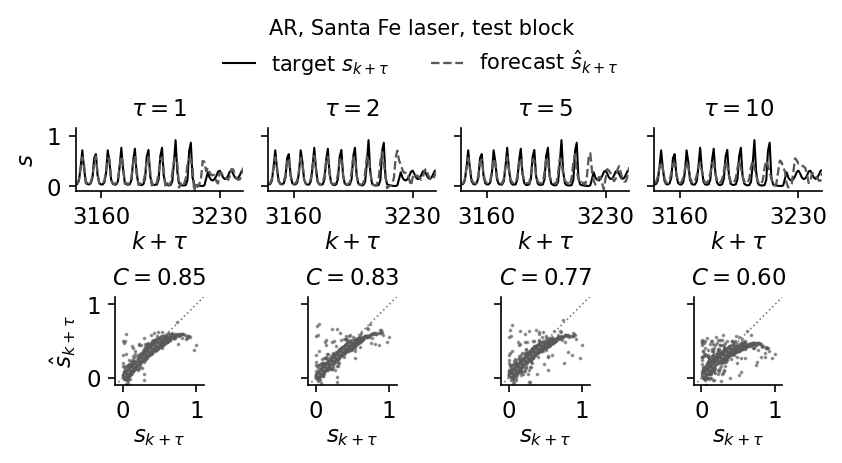

In [16]:
leads_figure("AR", "fig_lab037_leads_ar")
print("Santa Fe C(tau) at tau = 1, 2, 5, 10")
for m in ("AR", "MLP"):
    print(f"{m:6s}" + "".join(f"{nums['leads'][f'SantaFe {m} {t}']:8.3f}" for t in TAU_SHOW))

The AR forecast reproduces the pulsation phase and the moderate pulses. It stays below the largest pulses before the collapse, and after the collapse it predicts a further large pulse at all four leads. In the scatter plots the forecasts level off near 0.6 for the largest targets, and at $\tau=10$ the cloud becomes a broad band. A linear combination of past values cannot produce the outward spiral and the collapse of the delay plot together, and the least-squares compromise pulls large pulses towards the mean.

### Large pulses

We quantify this compression at $\tau=5$ with the test targets in the top 10 % of the target distribution and compare the average forecast for them with their average true value.

In [17]:
# mean forecast for the largest pulses: targets in the top 10 % of the test targets at tau = 5
t = 5
y_t = Yt_sf[:, t - 1]
big = y_t > np.quantile(y_t, 0.9)
nums["big_pulses_tau5"] = {"target_mean": float(y_t[big].mean())}
print(f"tau = {t}: {big.sum()} test targets above the 90 % quantile {np.quantile(y_t, 0.9):.2f}, mean target {y_t[big].mean():.3f}")
for m in ("AR", "NVAR", "MLP"):
    y_p = res["SantaFe"][m]["pred"][:, t - 1]
    nums["big_pulses_tau5"][m] = float(y_p[big].mean())
    print(f"    {m:5s} mean forecast {y_p[big].mean():.3f}")

tau = 5: 92 test targets above the 90 % quantile 0.55, mean target 0.678
    AR    mean forecast 0.517
    NVAR  mean forecast 0.636
    MLP   mean forecast 0.609


For the 92 largest targets, with mean value 0.68, the AR forecast averages 0.52, NVAR 0.64 and the MLP 0.61. Both nonlinear models recover most of the pulse height that the linear model loses, and NVAR, with its explicit quadratic terms, slightly more than the MLP at this lead.

<hr/>
## 6. MLP with scikit-learn

The same forecaster is available in scikit-learn as `MLPRegressor`, which accepts a target array with 50 columns and then has 50 linear outputs. We choose one hidden layer of 64 tanh units, the Adam optimiser with learning rate $5\times10^{-3}$, minibatches of 128 windows and `alpha=0`, which removes the L2 weight penalty that scikit-learn otherwise adds. The built-in early stopping of `MLPRegressor` holds out a random fraction of the training windows, which would mix windows from the whole training block into the validation set. We therefore call `partial_fit` once per epoch, one pass over the shuffled fitting windows, and apply the same early stopping on the chronological validation origins as for the JAX model, at most 250 epochs with a patience of 20. Three differences remain, since scikit-learn draws the initial weights uniformly in $\pm\sqrt{6/(n_{\rm in}+n_{\rm out})}$, computes in float64 and applies no gradient clipping. We train three seeds on the laser.

In [18]:
def fit_sklearn_mlp(s, seed=0, n_hid=N_HID, epochs=MAX_EPOCHS, patience=PATIENCE):
    # MLPRegressor with the same architecture, optimiser, learning rate, minibatch size and epoch budget;
    # one partial_fit call = one epoch over the shuffled fitting windows, early stopping on our validation origins
    Uf, Yf = windows(s, K_FIT); Uv, Yv = windows(s, K_VAL)
    m = MLPRegressor(hidden_layer_sizes=(n_hid,), activation="tanh", solver="adam", alpha=0.0,
                     batch_size=BATCH, learning_rate_init=LR, shuffle=True, random_state=seed)
    hist = dict(train=[], val=[])
    best_val, best_model, best_ep, t0 = np.inf, None, 0, time.time()
    for ep in range(epochs):
        m.partial_fit(Uf, Yf)
        hist["train"].append(2 * m.loss_)                      # scikit-learn reports half the mean-square error
        hist["val"].append(float(np.mean((m.predict(Uv) - Yv) ** 2)))
        if hist["val"][-1] < best_val:
            best_val, best_model, best_ep = hist["val"][-1], copy.deepcopy(m), ep
        elif ep - best_ep >= patience:
            break
    hist = {k: np.array(v) for k, v in hist.items()}
    hist.update(best_epoch=best_ep + 1, epochs_run=ep + 1, time=time.time() - t0, best_val=best_val)
    return best_model, hist

sk_runs = []
for seed in (0, 1, 2):
    m_sk, h_sk = fit_sklearn_mlp(sig["SantaFe"], seed=seed)
    sc_sk = score(m_sk.predict(windows(sig["SantaFe"], K_TEST)[0]), Yt_sf)
    sk_runs.append((m_sk, h_sk, sc_sk))
    print(f"scikit-learn MLPRegressor, seed {seed}: {h_sk['epochs_run']} epochs (best {h_sk['best_epoch']}),"
          f" best validation loss {h_sk['best_val']:.2e}, test C_tot {sc_sk['Ctot']:.1f}, {h_sk['time']:.1f} s")
n_sk = sum(c.size for c in sk_runs[0][0].coefs_) + sum(b.size for b in sk_runs[0][0].intercepts_)
print(f"parameters of MLPRegressor: {n_sk}")
m_sk, h_sk, sc_sk = sk_runs[0]
res["SantaFe"]["sklearn MLP"] = dict(pred=m_sk.predict(windows(sig["SantaFe"], K_TEST)[0]), **sc_sk)
nums["sklearn_santafe"] = dict(Ctot=[r[2]["Ctot"] for r in sk_runs], epochs=[r[1]["epochs_run"] for r in sk_runs],
                               best_epoch=[r[1]["best_epoch"] for r in sk_runs], n_params=n_sk,
                               time_s=[r[1]["time"] for r in sk_runs], tau_half=sc_sk["tau_half"])

scikit-learn MLPRegressor, seed 0: 250 epochs (best 248), best validation loss 1.01e-02, test C_tot 36.3, 6.4 s
scikit-learn MLPRegressor, seed 1: 250 epochs (best 250), best validation loss 1.05e-02, test C_tot 36.0, 7.0 s
scikit-learn MLPRegressor, seed 2: 250 epochs (best 250), best validation loss 1.11e-02, test C_tot 35.5, 6.4 s
parameters of MLPRegressor: 7410


The scikit-learn network has the same 7410 parameters. Its test $C_{\rm tot}$ lies between 35.5 and 36.3 for the three seeds, inside or close to the range 35.3 to 36.2 of the five JAX seeds, and like the JAX model it reaches its best validation loss in the last few of its 250 epochs. The scikit-learn fits took 6.4–7.0 seconds in this recorded run, compared with 4.5 seconds for the first JAX fit. We compare the validation loss per epoch of the two implementations for seed 0 and plot their capacity curves together with NVAR.

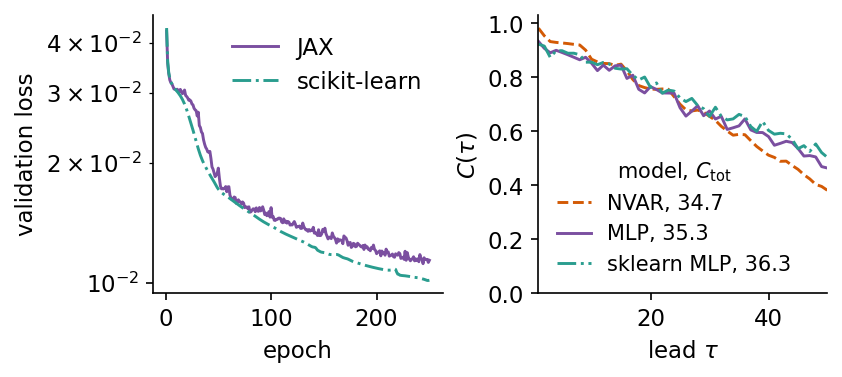

In [19]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    ep = np.arange(1, MAX_EPOCHS + 1)
    axs[0].semilogy(np.arange(1, hist_sf["epochs_run"] + 1), hist_sf["val"], color=STYLE["MLP"]["color"], label="JAX")
    axs[0].semilogy(np.arange(1, h_sk["epochs_run"] + 1), h_sk["val"], color=STYLE["sklearn MLP"]["color"], ls="-.", label="scikit-learn")
    axs[0].set_xlabel("epoch"); axs[0].set_ylabel("validation loss"); axs[0].legend(loc="upper right")
    for m in ("NVAR", "MLP", "sklearn MLP"):
        axs[1].plot(TAUS, res["SantaFe"][m]["C"], label=f"{m}, {res['SantaFe'][m]['Ctot']:.1f}", **STYLE[m])
    axs[1].set_xlim(1, TAU_MAX); axs[1].set_ylim(0, 1.03); axs[1].set_xlabel(r"lead $\tau$"); axs[1].set_ylabel(r"$C(\tau)$")
    axs[1].legend(loc="lower left", fontsize=10, handlelength=1.6, title=r"model, $C_{\rm tot}$", title_fontsize=10)
    save(fig, "fig_lab037_sklearn_mlp"); plt.show()

The two validation curves differ in detail, as expected from different initial weights and minibatch orders, and reach similar values after 250 epochs. The capacity curves of the two MLPs agree within the fluctuations of single fits, and both lie above NVAR at long leads. Within the seed spread the two implementations give the same result.

<hr/>
## 7. Hyperparameters and training

In each experiment we change one setting of the MLP and keep the others, and the fits in the window and width scans took 1.6–6.6 seconds each in this recorded run. A setting is normally chosen by the validation scores, and we show the test $C_{\rm tot}$ next to the validation $C_{\rm tot}$ to see how far the two agree. All fits use the same fitting origins, $k\ge63$, so only the window changes between them.

### Window length and hidden size

The window has to contain the part of the past that the forecast needs, and the hidden size sets the number of learned features. We first vary $L$ from 2 to 64 at $n_{\rm hid}=64$. For each fit we print the number of parameters, the epochs run and the best epoch, the best validation loss, and the validation and test $C_{\rm tot}$.

In [20]:
def val_ctot(model, d):
    return score(predict(model, d[2]), np.asarray(d[3], np.float64))["Ctot"]

def train_row(L, n_hid, seed=0):
    # one MLP fit with window L and n_hid hidden units; fitting origins start at the largest window used (64)
    d = net_data(sig["SantaFe"], L=L)
    m, h = fit_network(MLP(L, n_hid, TAU_MAX, rngs=nnx.Rngs(seed)), d[:4], seed=seed, verbose=False)
    return dict(L=L, n_hid=n_hid, seed=seed, params=n_params(m), best_val=h["best_val"], epochs=h["epochs_run"], best_epoch=h["best_epoch"],
                time=h["time"], val_Ctot=val_ctot(m, d), Ctot=score(predict(m, d[4]), np.asarray(d[5], np.float64))["Ctot"])

def print_row(r):
    print(f"L = {r['L']:2d}, n_hid = {r['n_hid']:3d}, seed {r['seed']}: {r['params']:6d} parameters, {r['epochs']:3d} epochs (best {r['best_epoch']:3d}),"
          f" best validation loss {r['best_val']:.2e}, validation C_tot {r['val_Ctot']:.1f}, test C_tot {r['Ctot']:.1f}, {r['time']:.1f} s")

L_GRID = (2, 4, 8, 16, 32, 64)
rows_L = []
for L_ in L_GRID:
    rows_L.append(train_row(L_, N_HID)); print_row(rows_L[-1])
nums["sweep_L"] = rows_L

L =  2, n_hid =  64, seed 0:   3442 parameters, 250 epochs (best 233), best validation loss 2.69e-02, validation C_tot 19.3, test C_tot 18.1, 3.3 s
L =  4, n_hid =  64, seed 0:   3570 parameters, 197 epochs (best 177), best validation loss 2.56e-02, validation C_tot 20.8, test C_tot 19.5, 3.0 s
L =  8, n_hid =  64, seed 0:   3826 parameters, 250 epochs (best 246), best validation loss 2.23e-02, validation C_tot 24.9, test C_tot 23.1, 3.2 s
L = 16, n_hid =  64, seed 0:   4338 parameters, 250 epochs (best 247), best validation loss 1.89e-02, validation C_tot 28.5, test C_tot 26.9, 2.6 s
L = 32, n_hid =  64, seed 0:   5362 parameters, 250 epochs (best 249), best validation loss 1.37e-02, validation C_tot 34.5, test C_tot 32.9, 2.9 s
L = 64, n_hid =  64, seed 0:   7410 parameters, 250 epochs (best 244), best validation loss 1.12e-02, validation C_tot 37.5, test C_tot 35.3, 2.7 s


The window length has a strong effect. In the second scan we vary $n_{\rm hid}$ from 2 to 256 at $L=64$.

In [21]:
H_GRID = (2, 4, 8, 16, 32, 64, 128, 256)
rows_H = []
for h_ in H_GRID:
    rows_H.append(train_row(L_WIN, h_)); print_row(rows_H[-1])
nums["sweep_hid"] = rows_H

L = 64, n_hid =   2, seed 0:    280 parameters, 102 epochs (best  82), best validation loss 3.08e-02, validation C_tot 14.7, test C_tot 14.6, 1.6 s
L = 64, n_hid =   4, seed 0:    510 parameters, 152 epochs (best 132), best validation loss 3.02e-02, validation C_tot 15.3, test C_tot 15.6, 2.0 s
L = 64, n_hid =   8, seed 0:    970 parameters, 250 epochs (best 247), best validation loss 1.62e-02, validation C_tot 31.5, test C_tot 28.6, 2.7 s
L = 64, n_hid =  16, seed 0:   1890 parameters, 250 epochs (best 248), best validation loss 1.37e-02, validation C_tot 34.3, test C_tot 32.1, 3.3 s
L = 64, n_hid =  32, seed 0:   3730 parameters, 250 epochs (best 249), best validation loss 1.15e-02, validation C_tot 37.0, test C_tot 34.8, 3.1 s
L = 64, n_hid =  64, seed 0:   7410 parameters, 250 epochs (best 244), best validation loss 1.12e-02, validation C_tot 37.5, test C_tot 35.3, 3.4 s
L = 64, n_hid = 128, seed 0:  14770 parameters, 250 epochs (best 244), best validation loss 1.05e-02, validation

We plot the validation and test $C_{\rm tot}$ of each fit for both scans, with the test values of AR and NVAR as horizontal lines.

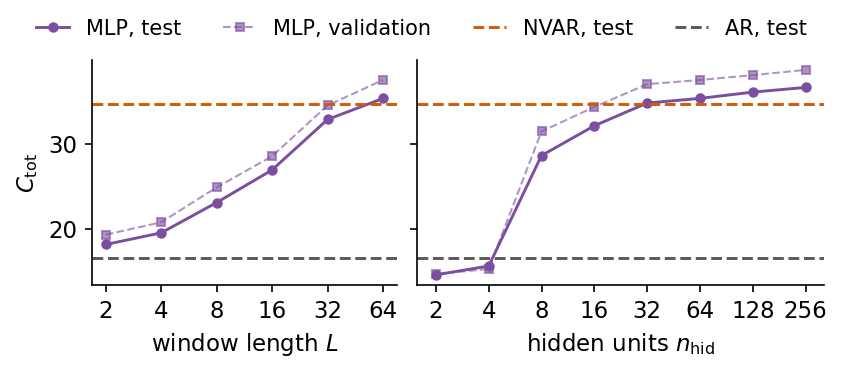

In [22]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained", sharey=True, gridspec_kw={"width_ratios": [6, 8]})
    for ax, rows, key, lab in ((axs[0], rows_L, "L", "window length $L$"), (axs[1], rows_H, "n_hid", r"hidden units $n_{\rm hid}$")):
        x = [r[key] for r in rows]
        ax.semilogx(x, [r["Ctot"] for r in rows], "o-", color=STYLE["MLP"]["color"], ms=4, label="MLP, test")
        ax.semilogx(x, [r["val_Ctot"] for r in rows], "s--", color=STYLE["MLP"]["color"], ms=3.5, alpha=0.6, lw=1.0,
                    label="MLP, validation")
        ax.axhline(res["SantaFe"]["NVAR"]["Ctot"], label="NVAR, test", **STYLE["NVAR"])
        ax.axhline(res["SantaFe"]["AR"]["Ctot"], label="AR, test", **STYLE["AR"])
        ax.set_xscale("log", base=2); ax.set_xticks(x); ax.set_xticklabels([str(v) for v in x])
        ax.set_xlabel(lab)
    axs[0].set_ylabel(r"$C_{\rm tot}$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=4, fontsize=10, handlelength=1.6)
    save(fig, "fig_lab037_sweeps"); plt.show()

The total capacity grows steadily with the window, from 18.1 at $L=2$ to 35.3 at $L=64$, and the MLP passes the NVAR value only with the longest window. The laser forecast therefore uses information spread over several pulsation periods. The hidden size shows a threshold. With two or four units the MLP is worse than the linear AR model on the same 64 values, eight units bring a jump to 28.6, and beyond 32 units the gain flattens, from 34.8 to 36.6 at 256 units with eight times as many parameters. The validation $C_{\rm tot}$ lies up to 3 units above the test value and follows it closely, so the validation block would select the same settings that the test block favours. Within the budget of 250 epochs no setting shows signs of overfitting, and the largest network is also the best on both blocks.

### Seed dependence

The seed fixes the random initial weights and the order of the minibatches. We repeat the default fit with five seeds.

In [23]:
SEEDS = (0, 1, 2, 3, 4)
rows_S = [train_row(L_WIN, N_HID, seed) for seed in SEEDS]
for r in rows_S:
    print_row(r)
v = np.array([r["Ctot"] for r in rows_S])
print(f"test C_tot over {len(SEEDS)} seeds: mean {v.mean():.1f}, standard deviation {v.std(ddof=1):.2f}, range {v.min():.1f}..{v.max():.1f}")
print(f"mean minus NVAR: {v.mean() - res['SantaFe']['NVAR']['Ctot']:.1f}")
nums["seeds"] = dict(Ctot=[float(x) for x in v], mean=float(v.mean()), std=float(v.std(ddof=1)),
                     min=float(v.min()), max=float(v.max()))

L = 64, n_hid =  64, seed 0:   7410 parameters, 250 epochs (best 244), best validation loss 1.12e-02, validation C_tot 37.5, test C_tot 35.3, 3.8 s
L = 64, n_hid =  64, seed 1:   7410 parameters, 250 epochs (best 247), best validation loss 1.08e-02, validation C_tot 37.7, test C_tot 35.6, 3.7 s
L = 64, n_hid =  64, seed 2:   7410 parameters, 250 epochs (best 245), best validation loss 1.05e-02, validation C_tot 38.1, test C_tot 36.0, 4.2 s
L = 64, n_hid =  64, seed 3:   7410 parameters, 250 epochs (best 249), best validation loss 1.06e-02, validation C_tot 38.0, test C_tot 36.2, 4.0 s
L = 64, n_hid =  64, seed 4:   7410 parameters, 250 epochs (best 250), best validation loss 1.07e-02, validation C_tot 37.8, test C_tot 36.0, 4.2 s
test C_tot over 5 seeds: mean 35.8, standard deviation 0.33, range 35.3..36.2
mean minus NVAR: 1.1


Over five seeds the test $C_{\rm tot}$ lies between 35.3 and 36.2, with mean 35.8 and standard deviation 0.33. Seed 0, used everywhere else, gives the lowest value of the five. Differences of less than about one unit between MLP settings are therefore within the seed spread, and the mean exceeds the NVAR value, 34.7, by 1.1, about three standard deviations.

### Training budget

The loss curves of Section 4 were still falling when the cap of 250 epochs stopped the training. We train the same network for at most 2000 epochs, with the patience set to the full budget so that the best validation epoch is always kept.

In [24]:
EPOCHS_LONG = 2000
m_long, h_long = fit_network(MLP(L_WIN, N_HID, TAU_MAX, rngs=nnx.Rngs(0)), data_sf[:4], seed=0,
                             epochs=EPOCHS_LONG, patience=EPOCHS_LONG)
C_long = score(predict(m_long, data_sf[4]), Yt_sf)["Ctot"]
print(f"validation loss {h_long['val'][MAX_EPOCHS - 1]:.2e} at epoch {MAX_EPOCHS}, best {h_long['best_val']:.2e} at epoch {h_long['best_epoch']}")
print(f"test C_tot {res['SantaFe']['MLP']['Ctot']:.1f} after at most {MAX_EPOCHS} epochs, {C_long:.1f} after at most {EPOCHS_LONG} epochs")
nums["long"] = dict(epochs=EPOCHS_LONG, best_epoch=h_long["best_epoch"], best_val=h_long["best_val"],
                    val_at_250=float(h_long["val"][MAX_EPOCHS - 1]), Ctot=C_long, time_s=h_long["time"])

    2000 epochs, best validation loss 7.29e-03 at epoch 1954, 21.9 s
validation loss 1.14e-02 at epoch 250, best 7.29e-03 at epoch 1954
test C_tot 35.3 after at most 250 epochs, 38.0 after at most 2000 epochs


We plot both losses over the 2000 epochs, with the dotted line at epoch 250 where the standard budget ends.

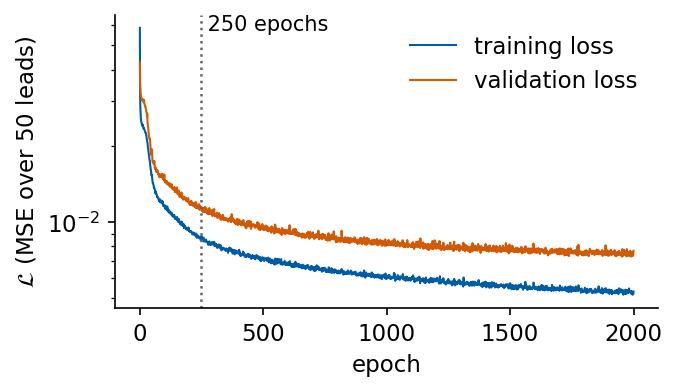

In [25]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    ep = np.arange(1, EPOCHS_LONG + 1)
    ax.semilogy(ep, h_long["train"], color=UJBlue, lw=1.0, label="training loss")
    ax.semilogy(ep, h_long["val"], color=DSOrange, lw=1.0, label="validation loss")
    ax.axvline(MAX_EPOCHS, color="0.4", ls=":", lw=1.2)
    ax.text(MAX_EPOCHS, ax.get_ylim()[1], f" {MAX_EPOCHS} epochs", va="top", ha="left", fontsize=10)
    ax.set_xlabel("epoch"); ax.set_ylabel(r"$\mathcal{L}$ (MSE over 50 leads)")
    ax.legend(loc="upper right")
    save(fig, "fig_lab037_long_training"); plt.show()

The validation loss keeps decreasing slowly, from $1.14\times10^{-2}$ at epoch 250 to $7.3\times10^{-3}$ at epoch 1954, and the test $C_{\rm tot}$ rises from 35.3 to 38.0, above NVAR by more than the seed spread. The value 35.3 is therefore a result of the training budget as well as of the model. Eight times more epochs give about three units of total capacity for this network, with a total training time of about 22 seconds in this recorded CPU run.

### Overfitting and early stopping

The network has no penalty on its weights, unlike the ridge models, and with enough parameters and few data it can fit the training windows ever better while the forecasts of new windows get worse. We provoke this regime with $n_{\rm hid}=256$, 29490 parameters, trained on the last 600 fitting origins only, for 2000 epochs without stopping, and we keep both the parameters of the best validation epoch and those of the last epoch.

In [26]:
N_BIG, N_SMALL_FIT, EPOCHS_OF = 256, 600, 2000
K_SMALL = K_FIT[-N_SMALL_FIT:]                                    # the last 600 fitting origins only
data_small = net_data(sig["SantaFe"], k_fit=K_SMALL)
m_big, h_big = fit_network(MLP(L_WIN, N_BIG, TAU_MAX, rngs=nnx.Rngs(0)), data_small[:4], seed=0,
                           epochs=EPOCHS_OF, patience=EPOCHS_OF, keep_last=True)
C_best = score(predict(m_big, data_small[4]), Yt_sf)["Ctot"]
C_last = score(predict(h_big["last_model"], data_small[4]), Yt_sf)["Ctot"]
print(f"MLP with {N_BIG} hidden units ({n_params(m_big)} parameters) on {N_SMALL_FIT} fitting windows, {EPOCHS_OF} epochs:")
print(f"    training loss {h_big['train'][h_big['best_epoch'] - 1]:.2e} at the best validation epoch {h_big['best_epoch']},"
      f" {h_big['train'][-1]:.2e} at epoch {EPOCHS_OF}")
print(f"    validation loss {h_big['best_val']:.2e} (best), {h_big['val'][-1]:.2e} at epoch {EPOCHS_OF}")
print(f"    test C_tot {C_best:.1f} with the best-validation parameters, {C_last:.1f} with the last parameters")
nums["overfit"] = dict(n_hid=N_BIG, n_fit=N_SMALL_FIT, params=n_params(m_big), epochs=EPOCHS_OF, best_epoch=h_big["best_epoch"],
                       best_val=h_big["best_val"], last_val=float(h_big["val"][-1]),
                       train_at_best=float(h_big["train"][h_big["best_epoch"] - 1]), last_train=float(h_big["train"][-1]),
                       Ctot_best=C_best, Ctot_last=C_last)

    2000 epochs, best validation loss 1.29e-02 at epoch 553, 10.6 s
MLP with 256 hidden units (29490 parameters) on 600 fitting windows, 2000 epochs:
    training loss 6.65e-03 at the best validation epoch 553, 3.27e-03 at epoch 2000
    validation loss 1.29e-02 (best), 1.81e-02 at epoch 2000
    test C_tot 34.0 with the best-validation parameters, 30.0 with the last parameters


We plot the training and validation losses of this run, with the dotted line at the epoch of the lowest validation loss.

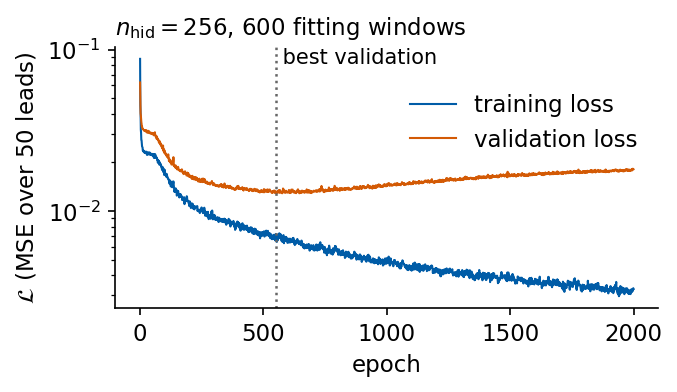

In [27]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    ep = np.arange(1, EPOCHS_OF + 1)
    ax.semilogy(ep, h_big["train"], color=UJBlue, lw=1.0, label="training loss")
    ax.semilogy(ep, h_big["val"], color=DSOrange, lw=1.0, label="validation loss")
    ax.axvline(h_big["best_epoch"], color="0.4", ls=":", lw=1.2)
    ax.text(h_big["best_epoch"], ax.get_ylim()[1], " best validation", va="top", ha="left", fontsize=10)
    ax.set_xlabel("epoch"); ax.set_ylabel(r"$\mathcal{L}$ (MSE over 50 leads)")
    ax.set_title(rf"$n_{{\rm hid}}={N_BIG}$, {N_SMALL_FIT} fitting windows", loc="left")
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.9))
    save(fig, "fig_lab037_overfitting"); plt.show()

The training loss falls from $6.7\times10^{-3}$ at the best validation epoch 553 to $3.3\times10^{-3}$ at epoch 2000, while the validation loss rises from $1.29\times10^{-2}$ to $1.81\times10^{-2}$. The network memorises the 600 training windows. With the parameters of the best validation epoch the test $C_{\rm tot}$ is 34.0, and with those of the last epoch it drops to 30.0. Early stopping on the validation loss recovers the better model at no extra cost. On the full training set the 256-unit network of the hidden-size scan reached its best validation loss in the last epochs of its 250, so there the amount of data kept it out of this regime within the budget.

<hr/>
## 8. Mackey–Glass delay equation

The Mackey–Glass equation
$$\dot s(t)=\frac{\beta\,s(t-\tau_{\rm MG})}{1+s(t-\tau_{\rm MG})^{10}}-\gamma\,s(t),\qquad \beta=0.2,\quad \gamma=0.1,$$
was proposed as a model of the regulation of blood cell production [Mackey and Glass, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)]. The first term is a production that responds to the state a delay $\tau_{\rm MG}$ earlier, and the second a decay at rate $\gamma$. Because of the delay the state of the system is the whole function $s$ on the interval $[t-\tau_{\rm MG},t]$, an infinite-dimensional phase space, the space of all possible states. Short delays give a stable limit cycle, a periodic oscillation that attracts nearby states, and longer delays give chaotic attractors, irregular sets of states on which the motion settles, whose dimension grows with the delay [Farmer, Physica D **4**, 366 (1982), [doi:10.1016/0167-2789(82)90042-2](https://doi.org/10.1016/0167-2789(82)90042-2)]. We compare the delays $\tau_{\rm MG}=15,25,35$, sampled once per time unit and rescaled like the laser.

For each delay we plot 500 samples of the signal and the delay plot of $s_k$ against $s_{k-17}$ on the training block. We use the same lag of 17 samples for all three delays.

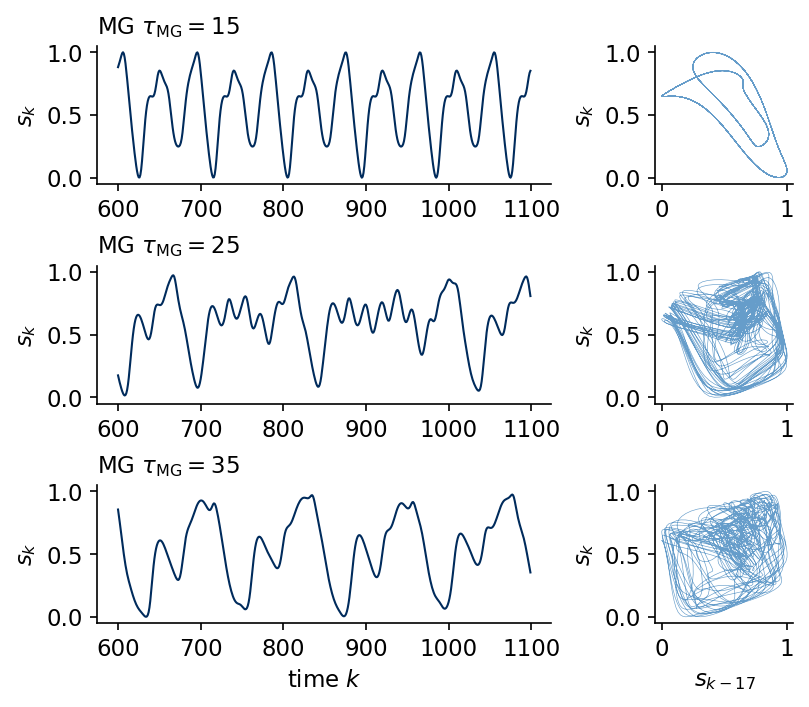

In [28]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 2, figsize=(5.5, 4.6), layout="constrained", gridspec_kw={"width_ratios": [2.2, 1]})
    for row, name in zip(axs, MG):
        s = sig[name]; kk = np.arange(600, 1100)
        row[0].plot(kk, s[kk], color=UJNavy, lw=1.0); row[0].set_ylabel("$s_k$")
        row[0].set_title(LABEL[name], loc="left"); row[0].set_ylim(-0.05, 1.05)
        k2 = np.arange(25, N_TRAIN)
        row[1].plot(s[k2 - 17], s[k2], lw=0.3, color=UJBlue, alpha=0.6)
        row[1].set_ylabel("$s_k$"); row[1].set_xlim(-0.05, 1.05); row[1].set_ylim(-0.05, 1.05); row[1].set_aspect("equal")
    axs[-1, 0].set_xlabel("time $k$"); axs[-1, 1].set_xlabel("$s_{k-17}$")
    save(fig, "fig_lab037_mg_signals"); plt.show()

At $\tau_{\rm MG}=15$ the signal repeats the same pattern of two maxima of different height, and its delay plot is a single closed curve. At $\tau_{\rm MG}=25$ and $35$ the oscillations are irregular and the delay plots fill bands of many nearby loops. A simple test of periodicity is the return distance $\max_k|s_{k+T}-s_k|$ over the test block, which vanishes for a period $T$ of the sampled signal. We compute its minimum over the return times $T=10,\dots,200$.

In [29]:
# smallest return distance max_k |s_{k+T} - s_k| over the test block, for return times T = 10..200
nums["mg_return"] = {}
for name in MG:
    s = sig[name][N_TRAIN:]
    d = np.array([np.abs(s[T:] - s[:-T]).max() for T in range(10, 201)])
    T_best = 10 + int(np.argmin(d))
    nums["mg_return"][name] = dict(T=T_best, dist=float(d.min()))
    print(f"{name}: smallest return distance {d.min():.1e} at T = {T_best}")

MG15: smallest return distance 1.3e-02 at T = 90
MG25: smallest return distance 5.7e-01 at T = 10
MG35: smallest return distance 4.6e-01 at T = 126


At $\tau_{\rm MG}=15$ the whole test block returns to within 0.013 of itself after $T=90$ samples, which is consistent with a limit cycle of period close to 90 time units. The small residual comes from sampling a period that need not be an integer number of time units. At the two longer delays the closest return within 200 samples misses by 0.57 and 0.46 on the rescaled scale, so no period up to 200 exists there, in line with the chaotic dynamics described by Farmer.

We train the MLP implementation in JAX and the scikit-learn `MLPRegressor` on each Mackey–Glass signal with the same settings and protocol as on the laser, and plot the capacity curves of all five models. For each fit we print the epochs run and the best epoch.

MG15: MLP 146 epochs (best 126), scikit-learn MLP 189 epochs (best 169)
MG25: MLP 250 epochs (best 241), scikit-learn MLP 140 epochs (best 120)
MG35: MLP 245 epochs (best 225), scikit-learn MLP 250 epochs (best 236)


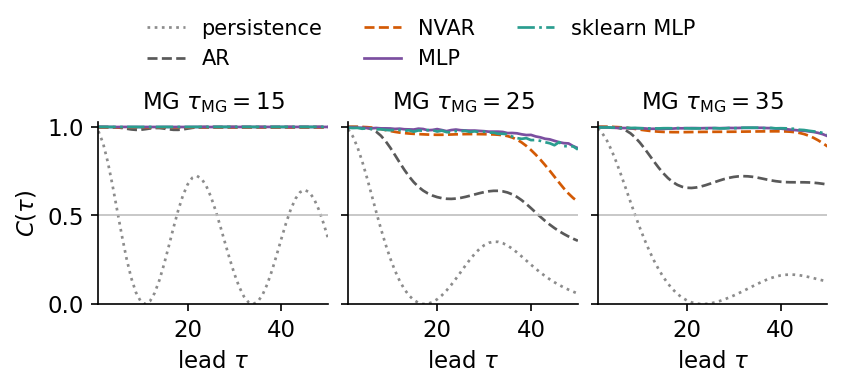

In [30]:
for name in MG:
    d_ = net_data(sig[name])
    Yt_ = np.asarray(d_[5], np.float64)
    m_, h_ = fit_network(MLP(L_WIN, N_HID, TAU_MAX, rngs=nnx.Rngs(0)), d_[:4], seed=0, verbose=False)
    res[name]["MLP"] = dict(pred=predict(m_, d_[4]), epochs=h_["epochs_run"], **score(predict(m_, d_[4]), Yt_))
    msk, hsk = fit_sklearn_mlp(sig[name], seed=0)
    P_sk = msk.predict(windows(sig[name], K_TEST)[0])
    res[name]["sklearn MLP"] = dict(pred=P_sk, epochs=hsk["epochs_run"], **score(P_sk, Yt_))
    print(f"{name}: MLP {h_['epochs_run']} epochs (best {h_['best_epoch']}), scikit-learn MLP {hsk['epochs_run']} epochs (best {hsk['best_epoch']})")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.5), layout="constrained", sharey=True)
    for ax, name in zip(axs, MG):
        for m in MODELS_ALL:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, label=m, **STYLE[m])
        ax.axhline(0.5, color="0.75", lw=0.8)
        ax.set_xlim(1, TAU_MAX); ax.set_ylim(0, 1.03); ax.set_xlabel(r"lead $\tau$"); ax.set_title(LABEL[name])
    axs[0].set_ylabel(r"$C(\tau)$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=10, handlelength=1.8)
    save(fig, "fig_lab037_capacity_mg"); plt.show()

We collect $C_{\rm tot}$, the skill horizon $\tau_{1/2}$ and $C(50)$ of all five models on all four signals in three tables.

In [31]:
ALL_SIG = ("SantaFe",) + MG
print(f"{'model':12s}" + "".join(f"{n:>10s}" for n in ALL_SIG) + "     (C_tot, maximum 50)")
for m in MODELS_ALL:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in ALL_SIG))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in ALL_SIG) + "     (tau_1/2, '>50' if C stays above 0.5)")
for m in MODELS_ALL:
    print(f"{m:12s}" + "".join(f"{(res[n][m]['tau_half'] or '>50'):>10}" for n in ALL_SIG))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in ALL_SIG) + "     (C at tau = 50)")
for m in MODELS_ALL:
    print(f"{m:12s}" + "".join(f"{res[n][m]['C'][-1]:10.3f}" for n in ALL_SIG))
nums["all"] = {n: {m: dict(Ctot=res[n][m]["Ctot"], tau_half=res[n][m]["tau_half"],
                           C={t: float(res[n][m]["C"][t - 1]) for t in (1, 2, 5, 10, 25, 50)}) for m in MODELS_ALL} for n in ALL_SIG}
nums["ridge_choice"] = {n: {m: dict(p=res[n][m]["p"], beta=res[n][m]["beta"], n_feat=res[n][m]["n_feat"])
                            for m in ("AR", "NVAR")} for n in ALL_SIG}

model          SantaFe      MG15      MG25      MG35     (C_tot, maximum 50)
persistence        5.5      19.5      13.3      11.8
AR                16.5      49.8      33.1      38.0
NVAR              34.7      50.0      45.5      48.6
MLP               35.3      50.0      48.4      49.5
sklearn MLP       36.3      50.0      47.9      49.5

model          SantaFe      MG15      MG25      MG35     (tau_1/2, '>50' if C stays above 0.5)
persistence          1         6         8        10
AR                  16       >50        42       >50
NVAR                42       >50       >50       >50
MLP                 49       >50       >50       >50
sklearn MLP        >50       >50       >50       >50

model          SantaFe      MG15      MG25      MG35     (C at tau = 50)
persistence      0.000     0.368     0.059     0.127
AR               0.056     1.000     0.357     0.675
NVAR             0.381     1.000     0.578     0.890
MLP              0.464     1.000     0.880     0.948
sklearn MLP

The four signals differ strongly in how hard they are to forecast within 50 leads.

The limit cycle at $\tau_{\rm MG}=15$ is the easiest. AR reaches $C_{\rm tot}=49.8$ and keeps $C(50)=1.000$, and NVAR and both MLPs reach 50.0. A periodic signal sampled finely is well described by a linear recurrence on its past values, so it needs no nonlinear features. Persistence, $C_{\rm tot}=19.5$, oscillates in the capacity figure because it compares the signal with a shifted copy of itself.

The two chaotic signals separate the linear from the nonlinear models. At $\tau_{\rm MG}=25$ AR drops to $C_{\rm tot}=33.1$ with $\tau_{1/2}=42$, NVAR reaches 45.5 with $C(50)=0.58$, and the two MLPs 48.4 and 47.9 with $C(50)$ near 0.88. At $\tau_{\rm MG}=35$ the values are 38.0 for AR, 48.6 for NVAR and 49.5 for both MLPs. Within 50 leads the longer delay is therefore the easier signal for every fitted model, although its attractor has the larger dimension. The capacity over a fixed range of leads depends on how fast nearby trajectories separate in units of the sampling time, measured by the largest Lyapunov exponent, the average rate at which nearby states separate, which the signals notebook finds smaller at $\tau_{\rm MG}=35$ than at $\tau_{\rm MG}=25$. On both chaotic signals the MLPs keep $C(\tau)$ above 0.85 at all leads, so the learned tanh features describe the smooth delayed nonlinearity better in this test than the quadratic monomials of the last 32 values.

The Santa Fe laser is the hardest of the four signals for every model. Its total capacities, 16.5 for AR and 35.3 to 36.3 for the MLPs, lie far below the Mackey–Glass values, since the collapses of the laser are rare irregular events whose timing the past window determines only approximately.

For each delay we plot the forecasts of the MLP and of AR at $\tau=1,2,5,10$. The upper row shows the target and both forecasts over the first 100 test targets starting at $k+\tau=3009$, the two lower rows plot each forecast against the target for all test origins, with $C(\tau)$ in the titles.

In [32]:
def leads_two_models(name, fname, models=("MLP", "AR"), k0=N_TRAIN + 10):
    # row 0: target and both forecasts on 100 test targets from k0; rows 1, 2: forecast vs target per model
    Yt_ = windows(sig[name], K_TEST)[1]
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(3, 4, figsize=(5.5, 4.1), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.3, 1.3]})
        for c_, t in enumerate(TAU_SHOW):
            a_t = axs[0, c_]
            i0 = k0 - t - K_TEST[0]
            kk = np.arange(k0, k0 + K_SHOW)
            a_t.plot(kk, Yt_[i0:i0 + K_SHOW, t - 1], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
            for m in models:
                a_t.plot(kk, res[name][m]["pred"][i0:i0 + K_SHOW, t - 1], color=STYLE[m]["color"], ls="--", lw=1.1,
                         label=f"{m} forecast")
            a_t.set_title(rf"$\tau={t}$"); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
            a_t.set_xlim(k0, k0 + K_SHOW - 1); a_t.set_xticks([k0 + 15, k0 + 85]); a_t.set_xlabel(r"$k+\tau$", labelpad=1)
            for r_, m in enumerate(models, start=1):
                a_s = axs[r_, c_]
                y_t, y_p = Yt_[:, t - 1], res[name][m]["pred"][:, t - 1]
                Cv = float(np.corrcoef(y_p, y_t)[0, 1] ** 2)
                nums.setdefault("leads", {})[f"{name} {m} {t}"] = Cv
                a_s.plot(y_t, y_p, ".", ms=1.5, color=STYLE[m]["color"], alpha=0.6)
                a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
                a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
                a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_title(f"{m}, $C={Cv:.2f}$", fontsize=10)
                if r_ == len(models): a_s.set_xlabel(r"$s_{k+\tau}$", labelpad=1)
                else: a_s.set_xticklabels([])
                if c_ == 0: a_s.set_ylabel(r"$\hat s_{k+\tau}$")
                else: a_s.set_yticklabels([])
            if c_ > 0: a_t.set_yticklabels([])
        axs[0, 0].set_ylabel("$s$")
        fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=3, fontsize=10,
                   handlelength=1.5, title=f"{LABEL[name]}, test block", title_fontsize=10)
        save(fig, fname); plt.show()
    print(f"{name} C(tau) at tau = 1, 2, 5, 10: " + " | ".join(
        f"{m} " + " ".join(f"{nums['leads'][f'{name} {m} {t}']:.3f}" for t in TAU_SHOW) for m in models))

MG15 C(tau) at tau = 1, 2, 5, 10: MLP 1.000 1.000 0.999 0.999 | AR 1.000 1.000 0.997 0.984


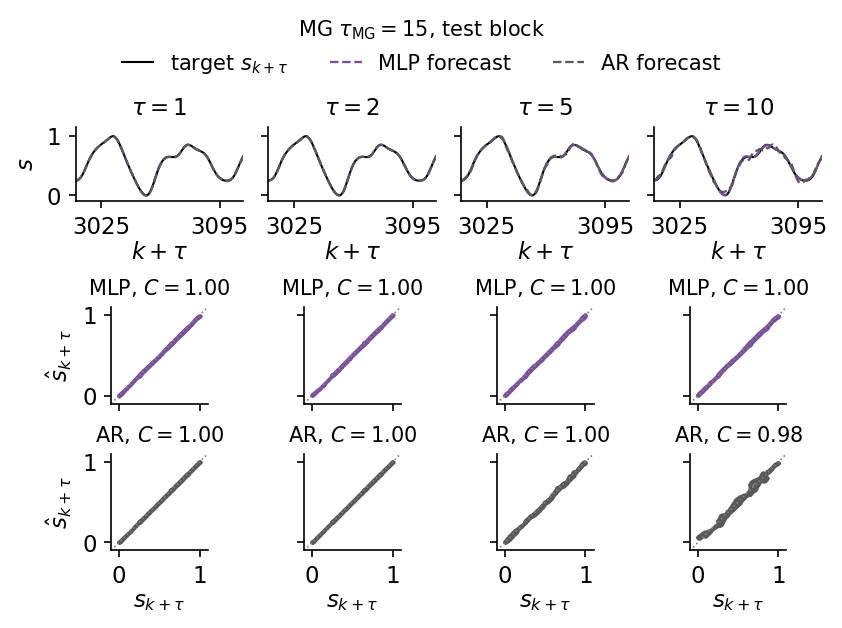

In [33]:
leads_two_models("MG15", "fig_lab037_leads_mg15")

On the limit cycle both models follow the target at all four leads, and the forecast curves lie on top of the target. The MLP keeps $C(\tau)\ge0.999$ up to $\tau=10$, and AR falls only slightly, to $0.984$ at $\tau=10$. A window of 64 values covers most of the period of 90 samples and fixes the position on the orbit.

MG25 C(tau) at tau = 1, 2, 5, 10: MLP 0.997 0.997 0.994 0.991 | AR 1.000 1.000 0.995 0.883


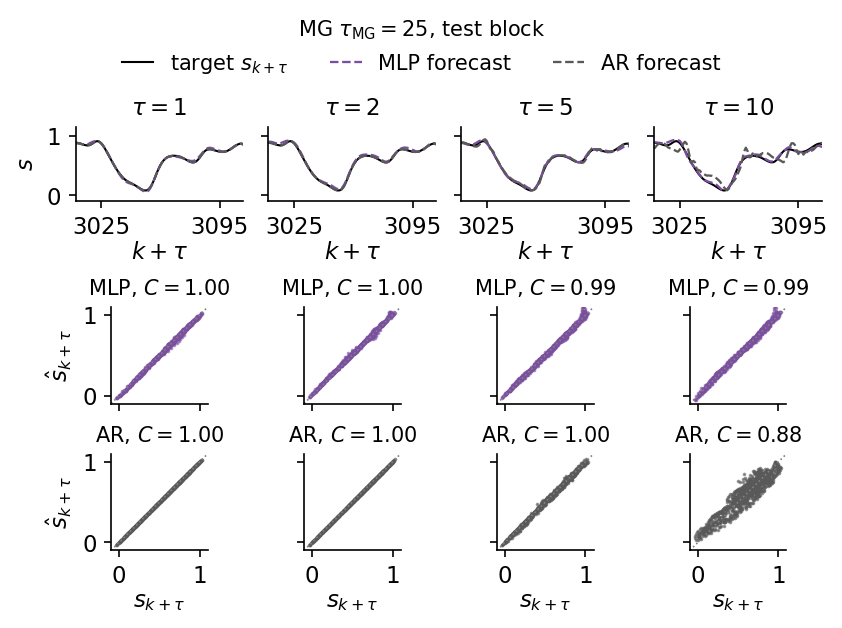

In [34]:
leads_two_models("MG25", "fig_lab037_leads_mg25")

At $\tau_{\rm MG}=25$ the AR forecast is as good as the MLP up to $\tau=5$, with $C=1.000$ at $\tau=1$ against $0.997$ for the MLP, so for the shortest leads the linear recurrence is slightly more accurate than the trained network. At $\tau=10$ the AR forecast deviates visibly from the target in the deep minimum and the scatter widens to a band with $C=0.88$, while the MLP stays at $0.99$. The nonlinearity of the delay equation matters once the forecast reaches several time units ahead.

MG35 C(tau) at tau = 1, 2, 5, 10: MLP 0.998 0.998 0.994 0.993 | AR 1.000 1.000 0.997 0.911


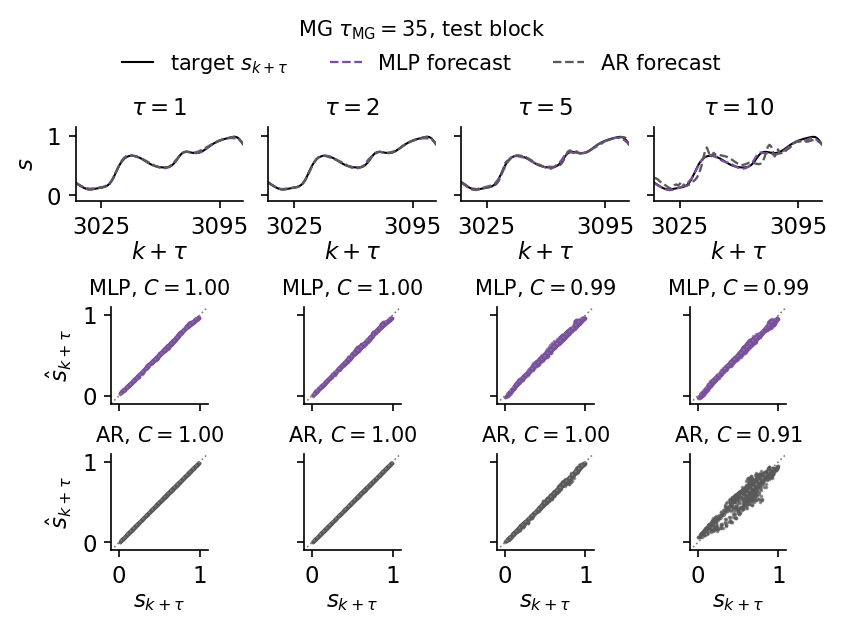

In [35]:
leads_two_models("MG35", "fig_lab037_leads_mg35")

The longest delay gives the same picture. AR reaches $C=1.000$ at the two shortest leads and $0.91$ at $\tau=10$, and the MLP keeps $C\ge0.993$ at all four leads. Compared with the laser, whose MLP capacity is already $0.85$ at $\tau=10$, the MLP forecasts of both chaotic Mackey–Glass signals remain close to the diagonal over this range of leads, and the gap between the linear and the nonlinear model grows with the lead.

We finally collect the forecasts of the MLP at the leads $\tau=1$, 5 and 10 on all four signals in one figure. Each row belongs to one signal and each column to one lead, and every panel shows the first 100 targets of the test block together with the forecast. The title of a panel gives the capacity $C(\tau)$ computed on the whole test block, so the four rows can be compared lead by lead.

MLP C(tau) on the test block
signal        C(1)    C(5)   C(10)
SantaFe      0.934   0.893   0.853
MG15         1.000   0.999   0.999
MG25         0.997   0.994   0.991
MG35         0.998   0.994   0.993


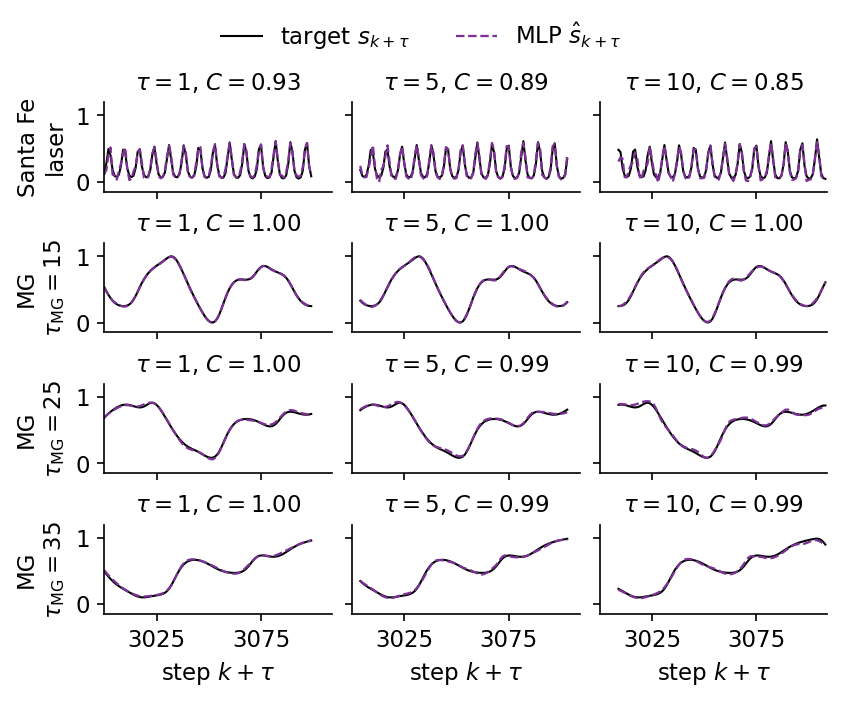

In [36]:
TAU_ALL = (1, 5, 10)
COL_MLP = "#7B3294"          # model colour shared by the summary figures of the MLP, RNN, LSTM and GRU notebooks
SIG_ALL = ("SantaFe", "MG15", "MG25", "MG35")
YLAB = {n: LABEL[n].replace(" $", "\n$").replace(" laser", "\nlaser") for n in SIG_ALL}   # signal label on two lines
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(len(SIG_ALL), len(TAU_ALL), figsize=(5.5, 4.6), layout="constrained")
    for r_, name in enumerate(SIG_ALL):
        Yt_ = windows(sig[name], K_TEST)[1]
        P_ = res[name]["MLP"]["pred"]
        for c_, t in enumerate(TAU_ALL):
            ax = axs[r_, c_]
            kk = K_TEST[:K_SHOW] + t                      # steps k + tau of the first 100 test targets
            ax.plot(kk, Yt_[:K_SHOW, t - 1], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
            ax.plot(kk, P_[:K_SHOW, t - 1], "--", color=COL_MLP, lw=1.1, label=r"MLP $\hat s_{k+\tau}$")
            ax.set_title(rf"$\tau={t}$, $C={res[name]['MLP']['C'][t - 1]:.2f}$")
            ax.set_ylim(-0.15, 1.2); ax.set_yticks([0, 1])
            ax.set_xlim(N_TRAIN, N_TRAIN + K_SHOW + max(TAU_ALL) - 1); ax.set_xticks([3025, 3075])
            if c_ == 0: ax.set_ylabel(YLAB[name])
            else: ax.set_yticklabels([])
            if r_ == len(SIG_ALL) - 1: ax.set_xlabel(r"step $k+\tau$")
            else: ax.set_xticklabels([])
    fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.8)
    save(fig, "fig_lab037_leads_all"); plt.show()

print(f"MLP C(tau) on the test block")
print(f"{'signal':10s}" + "".join(f"{'C(' + str(t) + ')':>8s}" for t in TAU_ALL))
for name in SIG_ALL:
    print(f"{name:10s}" + "".join(f"{res[name]['MLP']['C'][t - 1]:8.3f}" for t in TAU_ALL))


<hr/>
## Forecast accuracy and training dependence

We trained a multilayer perceptron with one tanh hidden layer as a direct forecaster of 50 leads from a window of 64 past values and scored it by the forecast capacity $C(\tau)=r(\tau)^2$ and its sum $C_{\rm tot}$. On the Santa Fe laser the linear AR model compresses the large pulses towards the mean and reaches $C_{\rm tot}=16.5$. Its forecasts cannot follow the outward spiral of the growing pulses and the collapse that ends it. The MLP with 7410 parameters reaches 35.3 under the standard budget of 250 epochs, close to NVAR with its 560 fixed quadratic features at 34.7, and it keeps $C(\tau)>0.5$ up to $\tau=49$.

The hyperparameter experiments identify the settings that matter for this signal. The total capacity grows with the window length up to the longest window tested, and the hidden layer needs about eight units before the MLP beats the linear model, with small gains beyond 32 units. The spread over five seeds is about a third of a unit. Longer training raises $C_{\rm tot}$ to 38.0, so the standard budget limits the result. Overfitting appears when a large network is trained for long on a quarter of the windows, and early stopping on the validation loss then keeps the better model, 34.0 against 30.0 at the last epoch. The `MLPRegressor` of scikit-learn, trained with the same protocol, gives 35.5 to 36.3 over three seeds, within about one unit of the JAX implementation.

The Mackey–Glass equation places the laser among simpler signals. The limit cycle at $\tau_{\rm MG}=15$ is forecast almost perfectly by every fitted model, AR included. At the chaotic delays 25 and 35 the AR capacity falls with the lead to $C_{\rm tot}=33.1$ and 38.0, while the MLPs reach 47.9 to 49.5 and stay above NVAR. The laser, with $C_{\rm tot}$ between 16.5 and 36.3 for the fitted models, is the hardest of the four signals. All results refer to these signals, this protocol and the settings tested here.

## References

- U. Hübner, N. B. Abraham, C. O. Weiss, *Dimensions and entropies of chaotic intensity pulsations in a single-mode far-infrared NH$_3$ laser*, Phys. Rev. A **40**, 6354 (1989), [doi:10.1103/PhysRevA.40.6354](https://doi.org/10.1103/PhysRevA.40.6354)
- A. S. Weigend, N. A. Gershenfeld (eds.), *Time Series Prediction. Forecasting the Future and Understanding the Past*, Santa Fe Institute Studies in the Sciences of Complexity **15**, Addison-Wesley (1994), reissued by Routledge (2018), [doi:10.4324/9780429492648](https://doi.org/10.4324/9780429492648)
- M. C. Mackey, L. Glass, *Oscillation and chaos in physiological control systems*, Science **197**, 287 (1977), [doi:10.1126/science.267326](https://doi.org/10.1126/science.267326)
- J. D. Farmer, *Chaotic attractors of an infinite-dimensional dynamical system*, Physica D **4**, 366 (1982), [doi:10.1016/0167-2789(82)90042-2](https://doi.org/10.1016/0167-2789(82)90042-2)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)
- G. Cybenko, *Approximation by superpositions of a sigmoidal function*, Math. Control Signals Syst. **2**, 303 (1989), [doi:10.1007/BF02551274](https://doi.org/10.1007/BF02551274)
- K. Hornik, *Approximation capabilities of multilayer feedforward networks*, Neural Netw. **4**, 251 (1991), [doi:10.1016/0893-6080(91)90009-T](https://doi.org/10.1016/0893-6080(91)90009-T)
- Y. LeCun, L. Bottou, G. B. Orr, K.-R. Müller, *Efficient BackProp*, in *Neural Networks: Tricks of the Trade*, LNCS **1524**, 9 (1998), [doi:10.1007/3-540-49430-8_2](https://doi.org/10.1007/3-540-49430-8_2)
- L. Prechelt, *Early stopping, but when?*, in *Neural Networks: Tricks of the Trade*, LNCS **1524**, 55 (1998), [doi:10.1007/3-540-49430-8_3](https://doi.org/10.1007/3-540-49430-8_3)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)

All numbers quoted in the text are stored in a JSON file and as LaTeX macros.

In [37]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(f"{OUT}/numbers_lab037.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

# LaTeX macros \labthreeseven... (letters only) for the numbers the slides use
SIGTAG = {"SantaFe": "SantaFe", "MG15": "MGfifteen", "MG25": "MGtwentyfive", "MG35": "MGthirtyfive"}
MODTAG = {"persistence": "Persistence", "AR": "AR", "NVAR": "NVAR", "MLP": "MLP", "sklearn MLP": "SklearnMLP"}
NUMTAG = {1: "One", 2: "Two", 4: "Four", 5: "Five", 8: "Eight", 10: "Ten", 16: "Sixteen", 25: "TwentyFive",
          32: "ThirtyTwo", 50: "Fifty", 64: "SixtyFour", 128: "OneTwentyEight", 256: "TwoFiftySix"}
macros = {}
for n in SIGTAG:
    for m in MODELS_ALL:
        macros[f"Ctot{MODTAG[m]}{SIGTAG[n]}"] = f"{res[n][m]['Ctot']:.1f}"
        th = res[n][m]["tau_half"]
        macros[f"TauHalf{MODTAG[m]}{SIGTAG[n]}"] = str(th) if th else "{>}50"
    for m in ("AR", "NVAR"):
        macros[f"Order{m}{SIGTAG[n]}"] = str(res[n][m]["p"])
for m in MODELS:
    for t in (1, 5, 10, 25, 50):
        macros[f"C{NUMTAG[t]}{MODTAG[m]}SantaFe"] = f"{res['SantaFe'][m]['C'][t - 1]:.2f}"
for k, val in nums["leads"].items():
    n, m, t = k.split()
    macros[f"Lead{m}{SIGTAG[n]}{NUMTAG[int(t)]}"] = f"{val:.2f}"
macros["PulsePeriod"] = str(nums["santafe_pulse_period"])
macros["ParamsMLP"] = str(nums["n_params_mlp"])
macros["EpochsRun"] = str(nums["santafe_main"]["epochs_run"])
macros["BestEpoch"] = str(nums["santafe_main"]["best_epoch"])
macros["FitTime"] = f"{nums['santafe_main']['time_s']:.1f}"
for r in rows_L:
    macros[f"SweepLCtot{NUMTAG.get(r['L'], 'Two' if r['L'] == 2 else str(r['L']))}"] = f"{r['Ctot']:.1f}"
for r in rows_H:
    macros[f"SweepHidCtot{NUMTAG.get(r['n_hid'], 'Two' if r['n_hid'] == 2 else str(r['n_hid']))}"] = f"{r['Ctot']:.1f}"
macros["SeedMean"] = f"{nums['seeds']['mean']:.1f}"
macros["SeedStd"] = f"{nums['seeds']['std']:.1f}"
macros["SeedMin"] = f"{nums['seeds']['min']:.1f}"
macros["SeedMax"] = f"{nums['seeds']['max']:.1f}"
macros["OverfitBestEpoch"] = str(nums["overfit"]["best_epoch"])
macros["OverfitCtotBest"] = f"{nums['overfit']['Ctot_best']:.1f}"
macros["OverfitCtotLast"] = f"{nums['overfit']['Ctot_last']:.1f}"
macros["OverfitParams"] = str(nums["overfit"]["params"])
macros["LongCtot"] = f"{nums['long']['Ctot']:.1f}"
macros["LongBestEpoch"] = str(nums["long"]["best_epoch"])
macros["BigPulseTarget"] = f"{nums['big_pulses_tau5']['target_mean']:.2f}"
for m in ("AR", "NVAR", "MLP"):
    macros[f"BigPulse{m}"] = f"{nums['big_pulses_tau5'][m]:.2f}"
for n in MG:
    for m in MODELS_ALL:
        macros[f"CFifty{MODTAG[m]}{SIGTAG[n]}"] = f"{res[n][m]['C'][-1]:.2f}"
v_sk = np.array(nums["sklearn_santafe"]["Ctot"])
macros["SklearnSeedMin"] = f"{v_sk.min():.1f}"; macros["SklearnSeedMax"] = f"{v_sk.max():.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab037.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labthreeseven{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

150 macros written; total runtime 3.8 min
